## LOADING OUR DATASET

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
apple = pd.read_csv("/content/drive/MyDrive/AppleData.csv")
google = pd.read_csv("/content/drive/MyDrive/GoogleData.csv")

DELETING ALL THE FREE APPS

In [ ]:
import pandas as pd

apple['Price'] = pd.to_numeric(apple['Price'], errors='coerce')
google['Price'] = pd.to_numeric(
    google['Price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False),
    errors='coerce'
)


apple = apple[apple['Price'] > 0].copy()
google = google[google['Price'] > 0].copy()

CHECKING AFTER DELETING

In [ ]:

print(f"Apple rows: {len(apple)}")
print(f"Google rows: {len(google)}")


print(f"Apple min price: {apple['Price'].min()}")
print(f"Google min price: {google['Price'].min()}")


print("Apple free apps left:", (apple['Price'] <= 0).sum())
print("Google free apps left:", (google['Price'] <= 0).sum())

Apple rows: 102502
Google rows: 44933
Apple min price: 0.99
Google min price: 0.194824
Apple free apps left: 0
Google free apps left: 0


# EDA AND PREPROCESSING and CLEANING

In [ ]:
apple.info()

<class 'pandas.core.frame.DataFrame'>
Index: 102502 entries, 3 to 1230355
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   App_Id                   102502 non-null  object 
 1   App_Name                 102502 non-null  object 
 2   AppStore_Url             102502 non-null  object 
 3   Primary_Genre            102502 non-null  object 
 4   Content_Rating           102502 non-null  object 
 5   Size_Bytes               102502 non-null  float64
 6   Required_IOS_Version     102502 non-null  object 
 7   Released                 102502 non-null  object 
 8   Updated                  102502 non-null  object 
 9   Version                  102502 non-null  object 
 10  Price                    102502 non-null  float64
 11  Currency                 102502 non-null  object 
 12  Free                     102502 non-null  bool   
 13  DeveloperId              102502 non-null  int64  
 14  Develope

In [ ]:
apple.isnull().sum()

,0
App_Id,0
App_Name,0
AppStore_Url,0
Primary_Genre,0
Content_Rating,0
Size_Bytes,0
Required_IOS_Version,0
Released,0
Updated,0
Version,0


DROPPING NULL VALUE COLUMNS

In [ ]:
apple= apple.drop('Developer_Website',axis=1)

In [ ]:
apple= apple.drop('Developer_Url',axis=1)

In [ ]:
apple = apple.dropna()

In [ ]:
google.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44933 entries, 273 to 2312927
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   App Name           44933 non-null  object 
 1   App Id             44933 non-null  object 
 2   Category           44933 non-null  object 
 3   Rating             44821 non-null  float64
 4   Rating Count       44821 non-null  float64
 5   Installs           44933 non-null  object 
 6   Minimum Installs   44933 non-null  float64
 7   Maximum Installs   44933 non-null  int64  
 8   Free               44933 non-null  bool   
 9   Price              44933 non-null  float64
 10  Currency           44933 non-null  object 
 11  Size               44932 non-null  object 
 12  Minimum Android    44655 non-null  object 
 13  Developer Id       44933 non-null  object 
 14  Developer Website  34319 non-null  object 
 15  Developer Email    44930 non-null  object 
 16  Released           4419

In [ ]:
google.isnull().sum()

,0
App Name,0
App Id,0
Category,0
Rating,112
Rating Count,112
Installs,0
Minimum Installs,0
Maximum Installs,0
Free,0
Price,0


In [ ]:
google= google.drop('Developer Website',axis=1)

In [ ]:
google = google.dropna()

In [ ]:
apple.head(10)

,App_Id,App_Name,AppStore_Url,Primary_Genre,Content_Rating,Size_Bytes,Required_IOS_Version,Released,Updated,Version,Price,Currency,Free,DeveloperId,Developer,Average_User_Rating,Reviews,Current_Version_Score,Current_Version_Reviews
3,fr.antoinettefleur.Book1,A-F Book #1,https://apps.apple.com/us/app/a-f-book-1/id500...,Book,4+,81851392.0,8.0,2012-02-10T03:40:07Z,2019-10-29T12:40:37Z,1.2,2.99,USD,False,439568839,i-editeur.com,0.00000,0,0.00000,0
12,com.laltrello.aabigbookandmore,AA Big Book and More,https://apps.apple.com/us/app/aa-big-book-and-...,Lifestyle,4+,3095552.0,9.0,2012-04-02T11:01:26Z,2017-04-11T03:25:00Z,4.0,1.99,USD,False,354615800,Rob Laltrello,4.67354,242,4.67354,242
13,com.aabigbook.appstore,AA Big Book App - Unofficial,https://apps.apple.com/us/app/aa-big-book-app-...,Book,17+,2094080.0,8.0,2015-12-19T00:41:11Z,2018-10-17T20:01:47Z,1.4.2,0.99,USD,False,295775659,Dean Huff,3.09524,21,3.09524,21
14,com.goodbarber.bigbookaudio,AA Big Book Audio (Unofficial),https://apps.apple.com/us/app/aa-big-book-audi...,Book,17+,45278208.0,11.0,2015-08-21T01:26:22Z,2019-05-22T19:01:40Z,1.2,4.99,USD,False,974773922,"Big Book Apps, LLC",3.88333,60,3.88333,60
15,com.goodbarber.aaid,AA Big Book Pro (Unofficial),https://apps.apple.com/us/app/aa-big-book-pro-...,Book,17+,80515072.0,10.0,2015-03-25T00:06:27Z,2018-10-05T17:11:09Z,1.6,4.99,USD,False,974773922,"Big Book Apps, LLC",4.13253,83,4.13253,83
23,dk.bodot.bforbear,B as Bear,https://apps.apple.com/us/app/b-as-bear/id1263...,Games,4+,76720128.0,9.3,2017-07-31T21:34:48Z,2020-08-18T16:40:55Z,1.1,0.99,USD,False,572272193,Bo Kalvslund,0.00000,0,0.00000,0
30,nl.gottmer.aadjepiraatje,Aadje Piraatje,https://apps.apple.com/us/app/aadje-piraatje/i...,Book,4+,217340928.0,8.0,2013-10-15T19:52:03Z,2021-02-11T12:39:23Z,2.7.5,1.99,USD,False,420385392,Gottmer Uitgevers Groep B.V.,0.00000,0,0.00000,0
32,com.jhdigitalsolutions.lastenaakkoset,Aakkospeli Lapsille,https://apps.apple.com/us/app/aakkospeli-lapsi...,Games,4+,71251968.0,7.0,2012-08-22T20:32:46Z,2015-10-11T14:06:03Z,1.4,1.99,USD,False,481610881,JH Digital Solutions,5.00000,1,5.00000,1
42,com.lettechnologies.Asan-Quran-by-Taqi-Usmani-Pro,Aasan Tarjuma e Quran -Tafseer,https://apps.apple.com/us/app/aasan-tarjuma-e-...,Education,4+,91656192.0,11.0,2020-04-05T07:00:00Z,2020-05-21T12:13:48Z,1.0.1,0.99,USD,False,1097519044,Akhzar Nazir,3.00000,2,3.00000,2
76,com.smartappsforkidseducation.firstcvcphonics,ABC 3 Letters Kids Phonics Fun,https://apps.apple.com/us/app/abc-3-letters-ki...,Education,4+,66067456.0,8.0,2018-01-17T19:03:37Z,2020-12-29T17:34:43Z,2.0.1,1.99,USD,False,1102699646,Anubha Goel,0.00000,0,0.00000,0


In [ ]:
google.head(10)

,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,...,Developer Id,Developer Email,Released,Last Updated,Content Rating,Privacy Policy,Ad Supported,In App Purchases,Editors Choice,Scraped Time
273,Limitless Paint,com.bytescaffold.limitlesspaint,Tools,4.5,236.0,"10,000+",10000.0,34125,False,1.99,...,Bitscaffold,traista.rafael@yahoo.com,"Nov 30, 2018","Apr 08, 2019",Everyone,http://htmlpreview.github.io/?https://github.c...,False,False,False,2021-06-15 20:19:52
296,Standalone Golf GPS by Hole19,com.hole19golf.wear,Sports,2.8,160.0,"10,000+",10000.0,10407,False,4.99,...,Hole19,help@hole19golf.com,"Feb 7, 2017","Dec 22, 2020",Everyone,https://www.hole19golf.com/terms/#PrivacyPolicy,False,False,False,2021-06-15 20:19:53
554,莎士比亞11連環錯（英漢對照）,tw.com.mebook.generic4719180217042,Education,0.0,0.0,1+,1.0,2,False,2.99,...,Soyong Corp.,welcome@mail.soyong.com.tw,"Mar 15, 2017","Mar 15, 2017",Everyone,http://mobile.mebook-buy.com/android/privacy.html,False,False,False,2021-06-15 20:20:07
618,Theme Park Simulator,com.bestridesimulators.theme.park.simulator.game,Simulation,3.8,1158.0,"10,000+",10000.0,23644,False,0.99,...,Best Ride Simulators,cuentas.brs@gmail.com,"Nov 3, 2020","Feb 05, 2021",Everyone,https://bestridesimulators.com/lunaria-games-s-l/,True,True,False,2021-06-15 20:20:11
637,Bukuu - Akibat Menipu,bukuu.com.my.siri.haiwan.akibat.menipu,Education,0.0,0.0,1+,1.0,2,False,1.99,...,MMSC Ventures Sdn Bhd,bukuu.mmsc@gmail.com,"Jan 12, 2016","Jan 13, 2016",Everyone,https://www.mmsc.com.my/bukuu/terma-penggunaan...,False,False,False,2021-06-15 20:20:13
661,JOTNA MEDIA GROUP,com.app.jotnamediagroupi,Business,4.9,19.0,100+,100.0,487,False,4.99,...,Zack Diop,kobe2die4@gmail.com,"Jun 15, 2020","Jun 15, 2020",Everyone,https://appcdn.media/privacy/?app=JOTNA%20MEDI...,True,False,False,2021-06-15 20:20:14
775,"Web Development PRO (HTML, CSS)",com.technoapps.webdevelopmentpro,Education,4.5,79.0,"5,000+",5000.0,7391,False,3.49,...,ArcX Dev,arcx.dev@gmail.com,"Dec 14, 2019","Dec 14, 2019",Everyone,https://technoapps92.blogspot.com/p/blog-page_...,False,False,False,2021-06-15 20:20:20
796,Kila: The Lazy Pig,kila.thelazypig,Books & Reference,0.0,0.0,1+,1.0,2,False,0.99,...,Kila,support@kilafun.com,"Aug 10, 2020","Aug 10, 2020",Everyone,http://www.kilafun.com/privacy/,False,False,False,2021-06-15 20:20:21
821,XBX and 5BX,app.li.xbxand5bx,Health & Fitness,0.0,0.0,100+,100.0,156,False,4.49,...,Lovell Innovations,contact@lovellinnovations.com,"Jan 2, 2021","May 14, 2021",Everyone,http://xbxand5bx.lovellinnovations.com/legal/p...,False,False,False,2021-06-15 20:20:23
839,Mr. Potato Head: School Rush,com.playdatedigital.potatohead,Education,3.5,44.0,"5,000+",5000.0,9486,False,3.99,...,PlayDate Digital Inc.,shaan@playdatedigital.com,"Jun 15, 2016","Nov 08, 2019",Everyone,http://playdatedigital.com/privacy-policy,False,False,False,2021-06-15 20:20:24


Data Cleaning and Column Standardization

In [ ]:
apple = apple.dropna(subset=['App_Name', 'Primary_Genre']).copy()
google = google.dropna(subset=['App Name', 'Category']).copy()

apple = apple.rename(columns={'App_Name': 'text', 'Primary_Genre': 'genre'})
google = google.rename(columns={'App Name': 'text', 'Category': 'genre'})

CATEGORY MAPPING FOR BOTH DATASETS

In [ ]:
category_mapping = {
    'Maps & Navigation': 'Navigation',
    'Travel & Local': 'Travel',
    'Books & Reference': 'Book',
    'House & Home': 'Lifestyle',
    'Educational': 'Education',
    'News & Magazines': 'News',
    'Music & Audio': 'Music'
}

google['genre'] = google['genre'].replace(category_mapping)

common_genres = sorted(list(set(apple['genre']).intersection(set(google['genre']))))
apple = apple[apple['genre'].isin(common_genres)].copy()
google = google[google['genre'].isin(common_genres)].copy()

CLEANING THE TEXTUAL FEATURES

In [ ]:
import re

def clean_app_title(text):
    text = str(text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip().lower()
    return text

apple['text_clean'] = apple['text'].apply(clean_app_title)
google['text_clean'] = google['text'].apply(clean_app_title)

apple = apple[apple['text_clean'] != ''].copy()
google = google[google['text_clean'] != ''].copy()

In [ ]:
print("Apple Apps")
print(apple.columns.tolist())

print("Google Apps")
print(google.columns.tolist())

Apple Apps
['App_Id', 'text', 'AppStore_Url', 'genre', 'Content_Rating', 'Size_Bytes', 'Required_IOS_Version', 'Released', 'Updated', 'Version', 'Price', 'Currency', 'Free', 'DeveloperId', 'Developer', 'Average_User_Rating', 'Reviews', 'Current_Version_Score', 'Current_Version_Reviews', 'text_clean']
Google Apps
['text', 'App Id', 'genre', 'Rating', 'Rating Count', 'Installs', 'Minimum Installs', 'Maximum Installs', 'Free', 'Price', 'Currency', 'Size', 'Minimum Android', 'Developer Id', 'Developer Email', 'Released', 'Last Updated', 'Content Rating', 'Privacy Policy', 'Ad Supported', 'In App Purchases', 'Editors Choice', 'Scraped Time', 'text_clean']


In [ ]:
print("Apple price examples:")
print(apple["Price"].head())

print("Google price examples:")
print(google["Price"].head())

Apple price examples:
3     2.99
12    1.99
13    0.99
14    4.99
15    4.99
Name: Price, dtype: float64
Google price examples:
296    4.99
554    2.99
637    1.99
661    4.99
775    3.49
Name: Price, dtype: float64


GOOGLES Price Data Cleaning and Statistical Summary

In [ ]:
google["Price"] = (
    google["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

google["Price"] = pd.to_numeric(google["Price"], errors="coerce")

print(google["Price"].describe())

count    16338.000000
mean         7.109401
std         19.664679
min          0.204735
25%          1.490000
50%          2.990000
75%          5.957500
max        400.000000
Name: Price, dtype: float64


In [ ]:
apple["Price"] = pd.to_numeric(apple["Price"], errors="coerce")

print(apple["Price"].describe())

count    57082.000000
mean         7.215342
std         26.122467
min          0.990000
25%          0.990000
50%          2.990000
75%          4.990000
max        999.990000
Name: Price, dtype: float64


DIVIDING INTO MULTICLASSES

In [ ]:
def make_price_class(price):
    if price < 3:
        return "Cheap"
    elif price < 9:
        return "Mid"
    else:
        return "Expensive"

VISUALIZATION OF CLASSES

In [ ]:
google["Price_Class"] = google["Price"].apply(make_price_class)
apple["Price_Class"] = apple["Price"].apply(make_price_class)

print("GOOGLE PRICE CLASSES")
print(google["Price_Class"].value_counts())

print("\nAPPLE PRICE CLASSES")
print(apple["Price_Class"].value_counts())

GOOGLE PRICE CLASSES
Price_Class
Cheap        8646
Mid          5483
Expensive    2209
Name: count, dtype: int64

APPLE PRICE CLASSES
Price_Class
Cheap        33488
Mid          15242
Expensive     8352
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

DATASET SUMMARY

In [ ]:


print("Apple App Store Dataset")
print("=" * 40)
print("Rows:", apple.shape[0])
print("Columns:", apple.shape[1])
print("Missing values:", apple.isnull().sum().sum())
print("Duplicate rows:", apple.duplicated().sum())

print("\nGoogle Play Store Dataset")
print("=" * 40)
print("Rows:", google.shape[0])
print("Columns:", google.shape[1])
print("Missing values:", google.isnull().sum().sum())
print("Duplicate rows:", google.duplicated().sum())

Apple App Store Dataset
Rows: 57082
Columns: 21
Missing values: 0
Duplicate rows: 0

Google Play Store Dataset
Rows: 16338
Columns: 25
Missing values: 0
Duplicate rows: 0


In [ ]:


print("Apple Numerical Features")
display(apple.describe().T)

print("\nGoogle Numerical Features")
display(google.describe().T)

Apple Numerical Features


,count,mean,std,min,25%,50%,75%,max
Size_Bytes,57082.0,9.053405e+07,2.256908e+08,2.762800e+04,1.077222e+07,2.898637e+07,7.547162e+07,7.816272e+09
Price,57082.0,7.215342e+00,2.612247e+01,9.900000e-01,9.900000e-01,2.990000e+00,4.990000e+00,9.999900e+02
DeveloperId,57082.0,8.179658e+08,4.221393e+08,2.817317e+08,4.244824e+08,7.150287e+08,1.173950e+09,1.590132e+09
Average_User_Rating,57082.0,1.817160e+00,2.069572e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.090910e+00,5.000000e+00
Reviews,57082.0,6.629051e+01,2.011457e+03,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,2.762710e+05
Current_Version_Score,57082.0,1.817160e+00,2.069572e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.090910e+00,5.000000e+00
Current_Version_Reviews,57082.0,6.629051e+01,2.011457e+03,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,2.762710e+05



Google Numerical Features


,count,mean,std,min,25%,50%,75%,max
Rating,16338.0,2.040684,2.102471,0.000000,0.00,0.00,4.2000,5.0
Rating Count,16338.0,302.905864,2903.771204,0.000000,0.00,0.00,34.0000,191460.0
Minimum Installs,16338.0,5063.825805,65702.913503,0.000000,10.00,100.00,1000.0000,5000000.0
Maximum Installs,16338.0,8619.606133,90997.668346,0.000000,20.00,166.00,1291.0000,7040478.0
Price,16338.0,7.109401,19.664679,0.204735,1.49,2.99,5.9575,400.0


### Visualize top 10 genres for GOOGLE and APPLE

/tmp/ipykernel_437/4053161324.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='genre', data=google, order=google['genre'].value_counts().index[:10], palette='viridis')


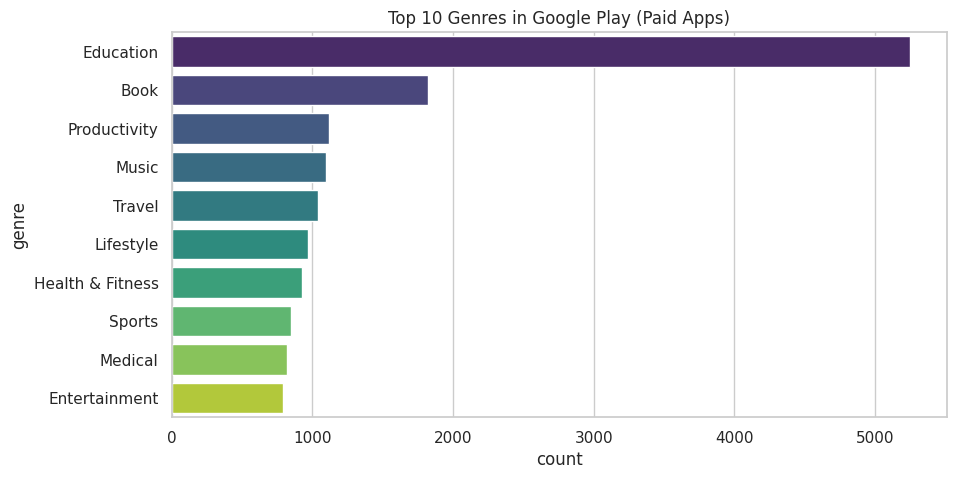

/tmp/ipykernel_437/4053161324.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='genre', data=apple, order=apple['genre'].value_counts().index[:10], palette='mako')


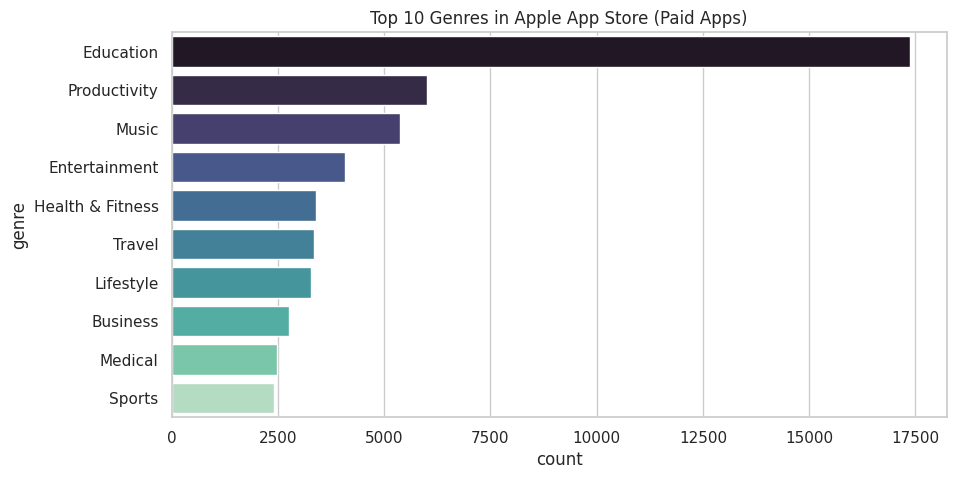

In [ ]:

plt.figure(figsize=(10, 5))
sns.countplot(y='genre', data=google, order=google['genre'].value_counts().index[:10], palette='viridis')
plt.title('Top 10 Genres in Google Play (Paid Apps)')
plt.show()


plt.figure(figsize=(10, 5))
sns.countplot(y='genre', data=apple, order=apple['genre'].value_counts().index[:10], palette='mako')
plt.title('Top 10 Genres in Apple App Store (Paid Apps)')
plt.show()

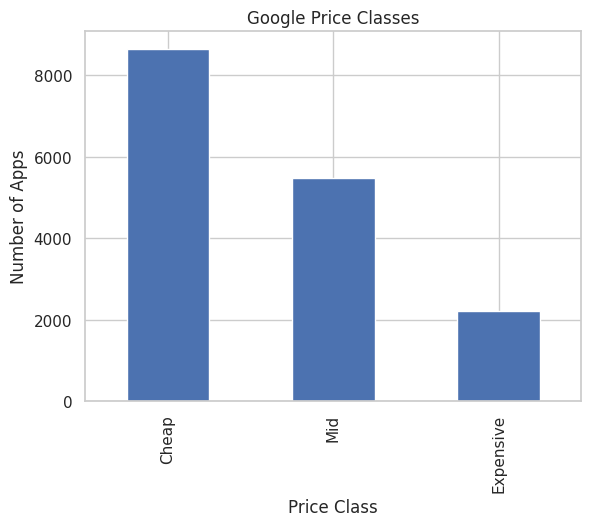

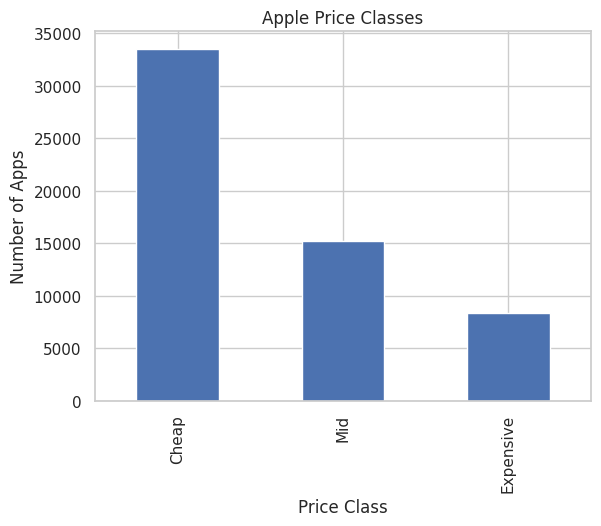

In [ ]:
google["Price_Class"].value_counts().plot(kind="bar")
plt.title("Google Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Apps")
plt.show()

apple["Price_Class"].value_counts().plot(kind="bar")
plt.title("Apple Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Apps")
plt.show()

In [ ]:
import numpy as np

In [ ]:
def google_size_to_mb(x):
    try:
        x = str(x).strip()

        if x.lower() == "nan":
            return np.nan

        if x.lower().endswith("m"):
            return float(x[:-1])

        if x.lower().endswith("k"):
            return float(x[:-1]) / 1024

        if x.lower().endswith("g"):
            return float(x[:-1]) * 1024

        return np.nan
    except:
        return np.nan

google["Size_MB"] = google["Size"].apply(google_size_to_mb)

In [ ]:

apple["Average User Rating"] = apple["Average_User_Rating"]


apple["Rating Count"] = pd.to_numeric(
    apple["Reviews"]
)


apple["Size_MB"] = pd.to_numeric(
    apple["Size_Bytes"]
) / (1024 * 1024)

In [ ]:
print("Google numerical data:")
print(google[["Rating", "Rating Count", "Size_MB"]].describe())

print("\nApple numerical data:")
print(apple[["Average User Rating", "Rating Count", "Size_MB"]].describe())

Google numerical data:
             Rating   Rating Count       Size_MB
count  16338.000000   16338.000000  15430.000000
mean       2.040684     302.905864     21.468916
std        2.102471    2903.771204     30.120055
min        0.000000       0.000000      0.007617
25%        0.000000       0.000000      4.200000
50%        0.000000       0.000000     11.000000
75%        4.200000      34.000000     28.750000
max        5.000000  191460.000000   1126.400000

Apple numerical data:
       Average User Rating   Rating Count       Size_MB
count         57082.000000   57082.000000  57082.000000
mean              1.817160      66.290512     86.339998
std               2.069572    2011.456693    215.235501
min               0.000000       0.000000      0.026348
25%               0.000000       0.000000     10.273193
50%               0.000000       0.000000     27.643555
75%               4.090910       4.000000     71.975342
max               5.000000  276271.000000   7454.177939


In [ ]:
apple_numeric = apple[
    ["Average User Rating", "Rating Count", "Size_MB", "Price_Class"]
].copy()

apple_numeric = apple_numeric.rename(
    columns={"Average User Rating": "Rating"}
)

google_numeric = google[
    ["Rating", "Rating Count", "Size_MB", "Price_Class"]
].copy()


In [ ]:
google_numeric = google_numeric.dropna(subset=["Price_Class"])
apple_numeric = apple_numeric.dropna(subset=["Price_Class"])

In [ ]:
for column in ["Rating", "Rating Count", "Size_MB"]:
    google_numeric[column] = google_numeric[column].fillna(
        google_numeric[column].median()
    )

    apple_numeric[column] = apple_numeric[column].fillna(
        apple_numeric[column].median()
    )


Distribution of Numeric Features

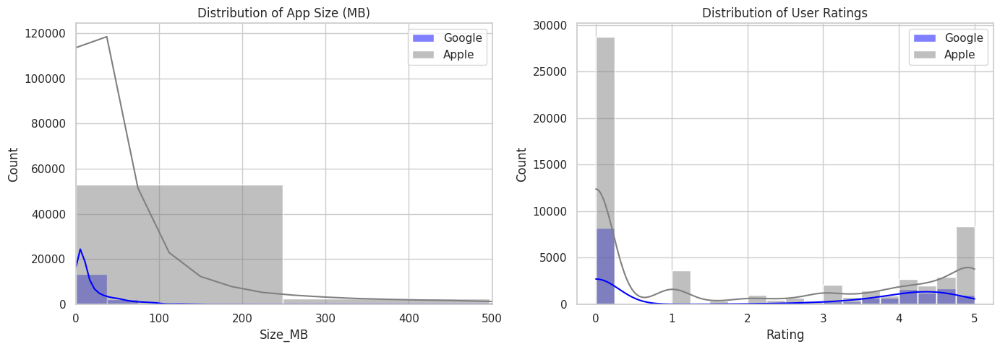

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.histplot(google_numeric['Size_MB'], bins=30, ax=axes[0], color='blue', kde=True, label='Google')
sns.histplot(apple_numeric['Size_MB'], bins=30, ax=axes[0], color='gray', kde=True, label='Apple', alpha=0.5)
axes[0].set_title('Distribution of App Size (MB)')
axes[0].set_xlim(0, 500)
axes[0].legend()


sns.histplot(google_numeric['Rating'], bins=20, ax=axes[1], color='blue', kde=True, label='Google')
sns.histplot(apple_numeric['Rating'], bins=20, ax=axes[1], color='gray', kde=True, label='Apple', alpha=0.5)
axes[1].set_title('Distribution of User Ratings')
axes[1].legend()

plt.tight_layout()
plt.show()

Box Plot

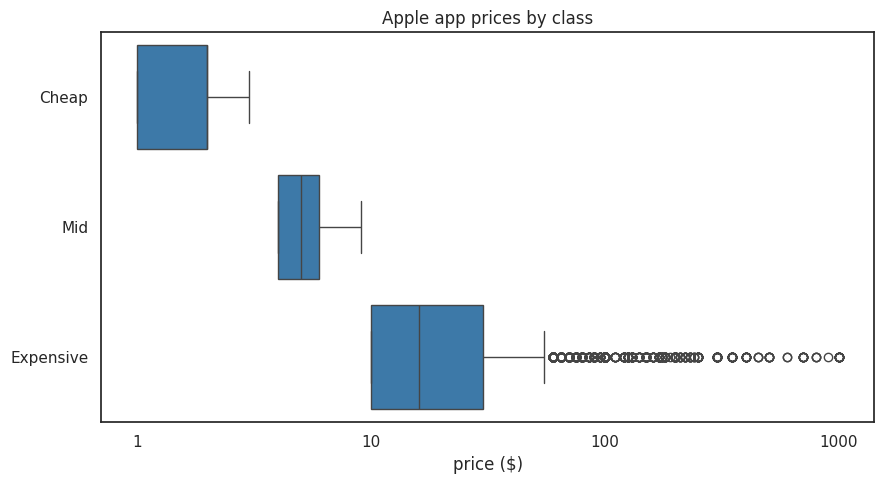

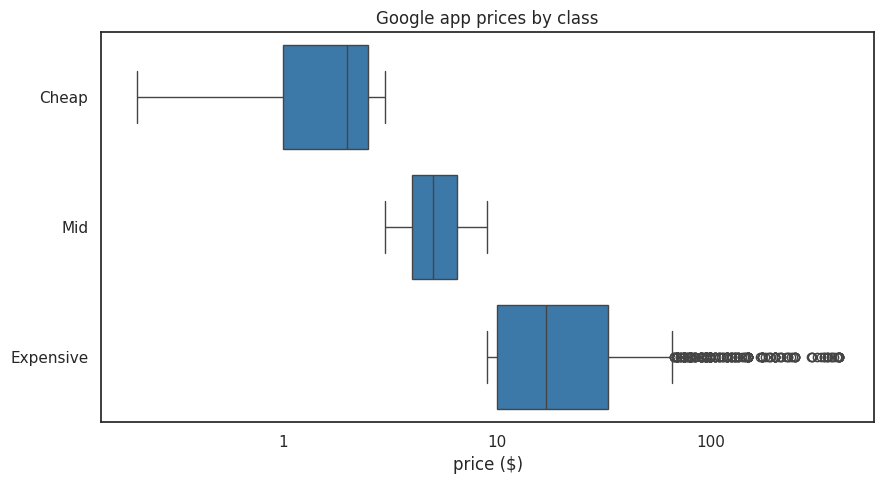

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")

price_order = ["Cheap", "Mid", "Expensive"]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=apple,
    x="Price",
    y="Price_Class",
    order=price_order,
    color="#2b7bba",
)

plt.xscale("log")
plt.title("Apple app prices by class")
plt.xlabel("price ($)")
plt.ylabel("")

from matplotlib.ticker import ScalarFormatter

plt.gca().xaxis.set_major_formatter(ScalarFormatter())

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=google,
    x="Price",
    y="Price_Class",
    order=price_order,
    color="#2b7bba",
)

plt.xscale("log")
plt.title("Google app prices by class")
plt.xlabel("price ($)")
plt.ylabel("")

plt.gca().xaxis.set_major_formatter(ScalarFormatter())

plt.tight_layout()
plt.show()

CORRELATION HEATMAP

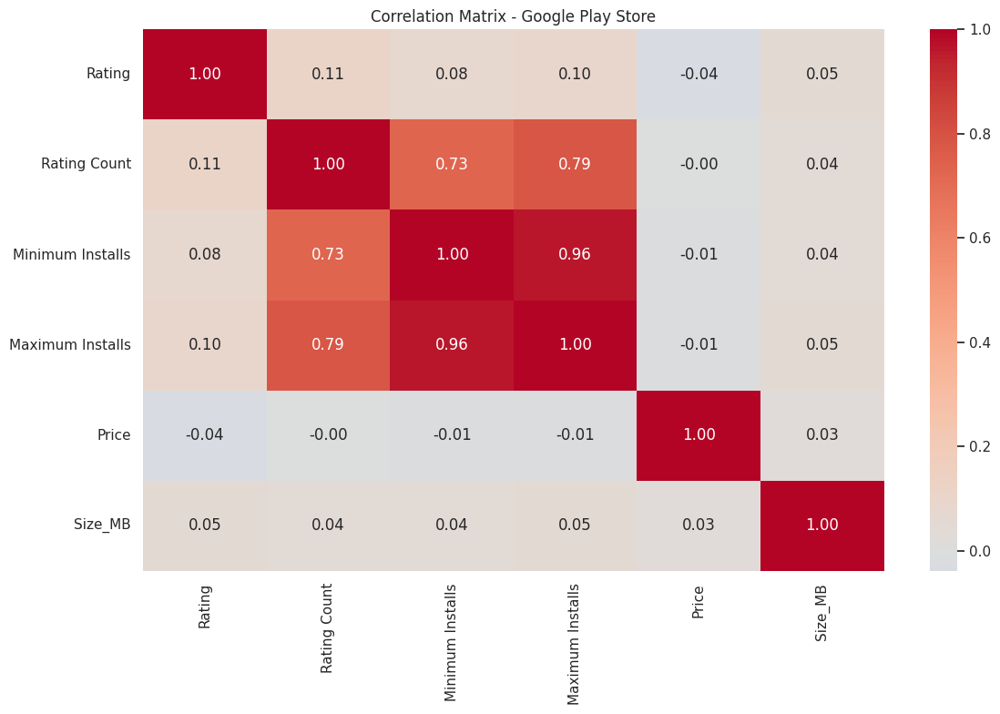

In [ ]:
#GOOGLE

google_numeric = google.select_dtypes(include='number')

google_corr = google_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    google_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix - Google Play Store')
plt.tight_layout()
plt.show()

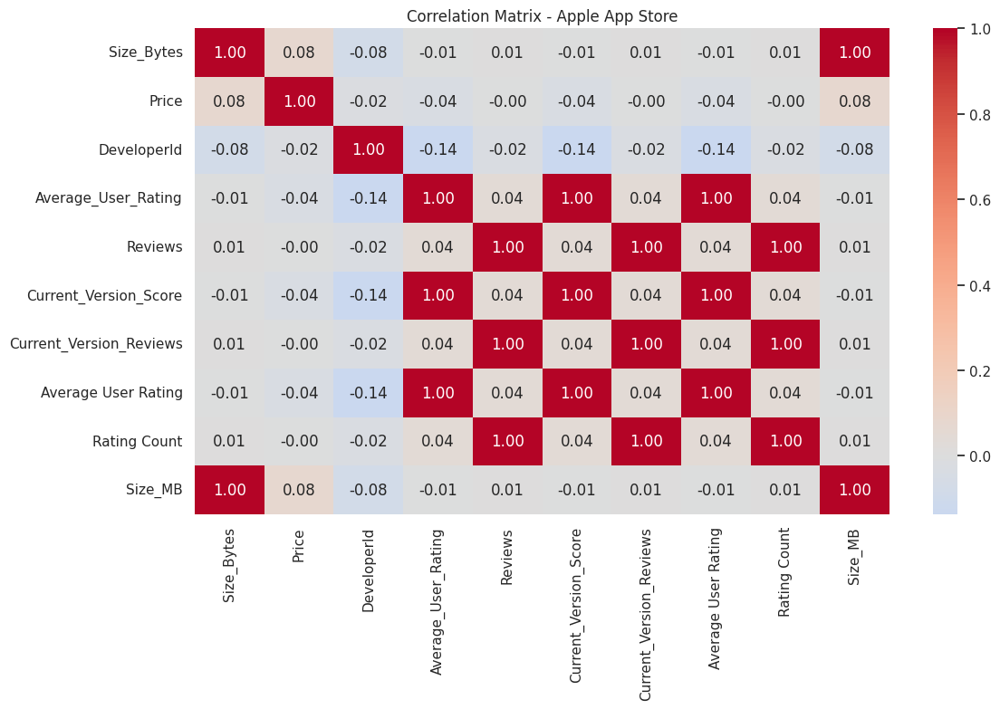

In [ ]:
#APPLE

apple_numeric = apple.select_dtypes(include='number')

apple_corr = apple_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    apple_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix - Apple App Store')
plt.tight_layout()
plt.show()

TFIDF AND WORD2VEC FOR TEXTUAL FEATURES

In [ ]:
!pip install gensim
import gensim
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer

def extract_tfidf_features(train_texts, test_texts, max_features=5000, ngram_range=(1, 2)):

    tfidf = TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        stop_words='english',
        sublinear_tf=True
    )

    X_train_tfidf = tfidf.fit_transform(train_texts.astype(str))
    X_test_tfidf = tfidf.transform(test_texts.astype(str))

    return X_train_tfidf, X_test_tfidf, tfidf


def _document_vector(tokens, w2v_model, embed_dim):

    vectors = [w2v_model.wv[word] for word in tokens if word in w2v_model.wv]
    if not vectors:
        return np.zeros(embed_dim)
    return np.mean(vectors, axis=0)

def extract_w2v_features(train_texts, test_texts, embed_dim=100, window=5, min_count=1):

    train_tokens = [str(text).lower().split() for text in train_texts]
    test_tokens = [str(text).lower().split() for text in test_texts]


    w2v_model = Word2Vec(
        sentences=train_tokens,
        vector_size=embed_dim,
        window=window,
        min_count=min_count,
        workers=4,
        sg=0
    )


    X_train_w2v = np.array([_document_vector(tokens, w2v_model, embed_dim) for tokens in train_tokens])
    X_test_w2v = np.array([_document_vector(tokens, w2v_model, embed_dim) for tokens in test_tokens])

    return X_train_w2v, X_test_w2v, w2v_model

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 32.6 MB/s eta 0:00:00


# **TRAINING AND TESTNG MODELS**

# Numerical — Same Platform

## Apple x Apple

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report


num_cols = ['Size_Bytes', 'Average_User_Rating', 'Reviews', 'Current_Version_Score', 'Current_Version_Reviews']


apple_num = apple.dropna(subset=num_cols + ['Price_Class']).copy()

if 'Free' in apple_num.columns:
    apple_num['Free'] = apple_num['Free'].astype(int)
    num_cols.append('Free')

X = apple_num[num_cols]
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(apple_num['Price_Class'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

--- Logistic Regression Performance (Apple Test Set) ---
Macro F1 Score: 0.3748

              precision    recall  f1-score   support

       Cheap       0.65      0.78      0.70      6698
   Expensive       0.19      0.24      0.21      1670
         Mid       0.36      0.15      0.21      3049

    accuracy                           0.53     11417
   macro avg       0.40      0.39      0.37     11417
weighted avg       0.50      0.53      0.50     11417



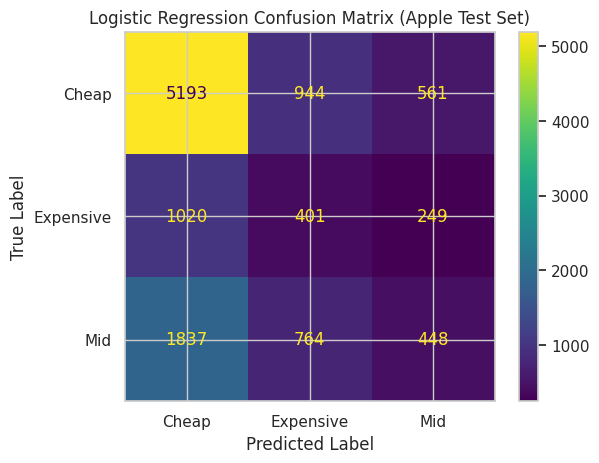

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)


macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Logistic Regression Performance (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')
plt.title("Logistic Regression Confusion Matrix (Apple Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

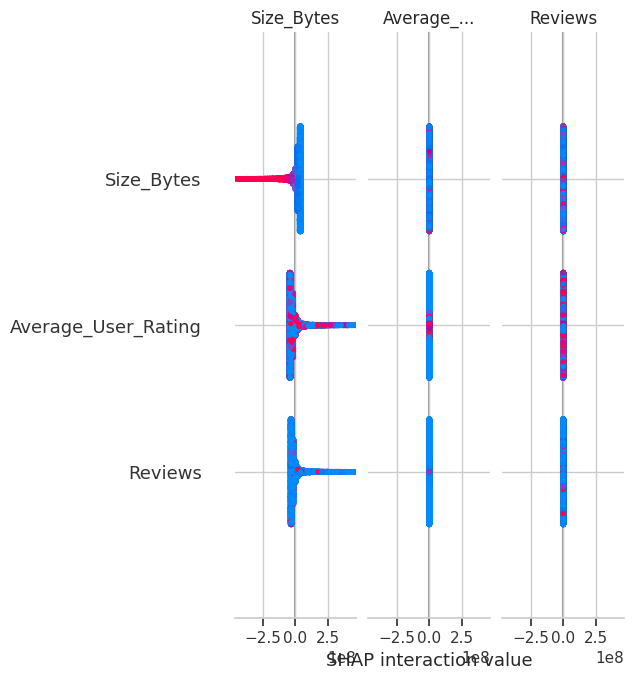

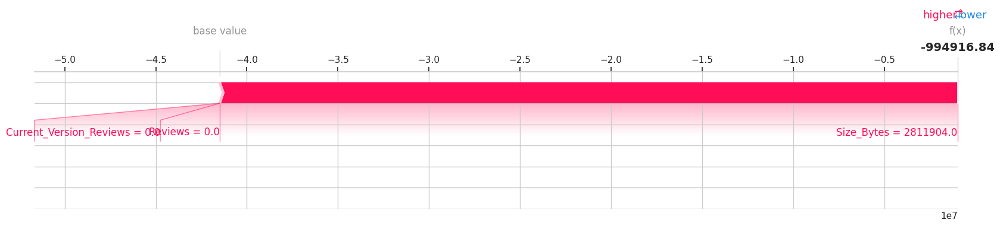

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)


sample_idx = 0
class_idx = 0


if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular

feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)

sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)

exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

Logistic Regression WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(
    C=0.1,
    max_iter=1000,
    class_weight=None,
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Logistic Regression Performance (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

--- Logistic Regression Performance (Apple Test Set) ---
Macro F1 Score: 0.2903

              precision    recall  f1-score   support

       Cheap       0.60      0.98      0.75      6698
   Expensive       0.67      0.00      0.00      1670
         Mid       0.50      0.07      0.12      3049

    accuracy                           0.60     11417
   macro avg       0.59      0.35      0.29     11417
weighted avg       0.58      0.60      0.47     11417



In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

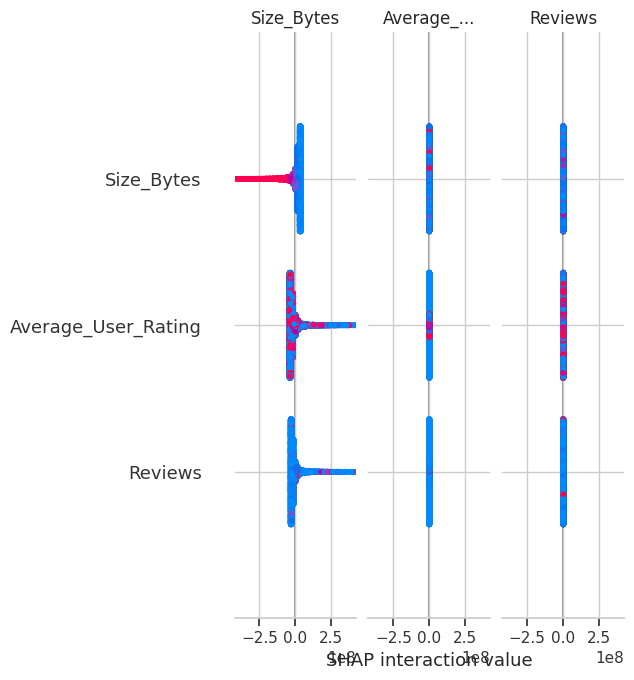

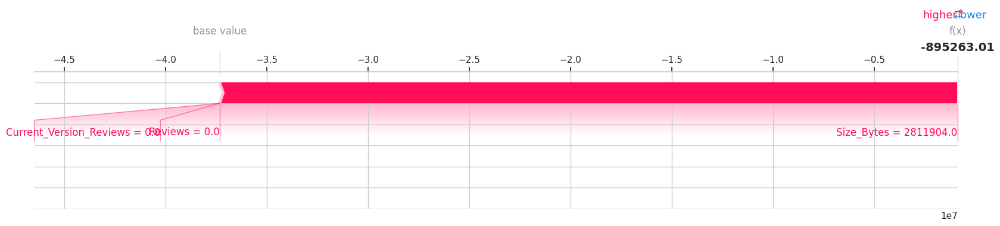

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)


sample_idx = 0
class_idx = 0


if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular


feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)


sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)


exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

macro_f1_rf = f1_score(y_test, y_pred_rf, average='macro')

print(f"--- Random Forest Performance (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_rf:.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))

--- Random Forest Performance (Apple Test Set) ---
Macro F1 Score: 0.3621

              precision    recall  f1-score   support

       Cheap       0.61      0.63      0.62      6698
   Expensive       0.18      0.17      0.18      1670
         Mid       0.29      0.28      0.28      3049

    accuracy                           0.47     11417
   macro avg       0.36      0.36      0.36     11417
weighted avg       0.46      0.47      0.47     11417



## Google x Google

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report

num_cols = ['Rating', 'Rating Count', 'Minimum Installs', 'Maximum Installs']
bool_cols = ['Free', 'Ad Supported', 'In App Purchases', 'Editors Choice']

google_num = google.dropna(subset=num_cols + ['Price_Class']).copy()
for col in bool_cols:
    if col in google_num.columns:
        google_num[col] = google_num[col].astype(int)

feature_cols = num_cols + [col for col in bool_cols if col in google_num.columns]

X = google_num[feature_cols]
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(google_num['Price_Class'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Logistic Regression Performance (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

--- Logistic Regression Performance (Google Test Set) ---
Macro F1 Score: 0.3602

              precision    recall  f1-score   support

       Cheap       0.57      0.53      0.55      1729
   Expensive       0.23      0.06      0.10       442
         Mid       0.37      0.52      0.43      1097

    accuracy                           0.46      3268
   macro avg       0.39      0.37      0.36      3268
weighted avg       0.46      0.46      0.45      3268



In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

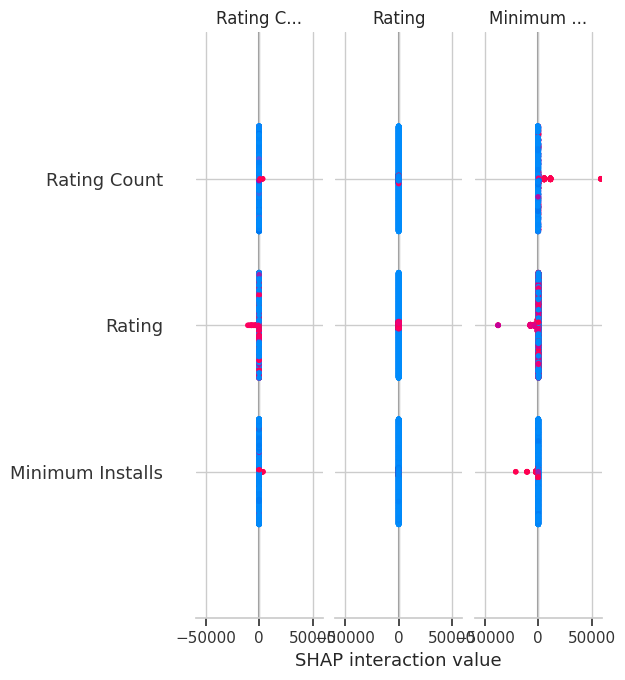

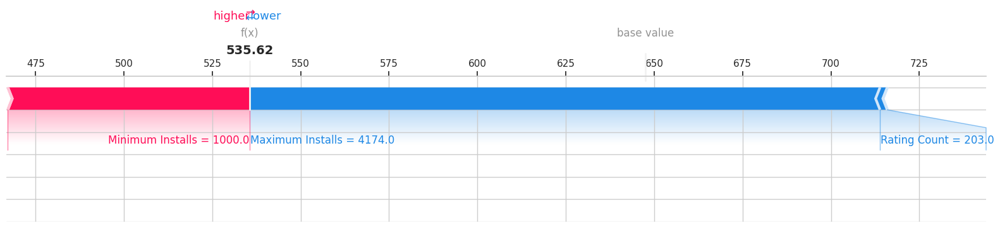

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)


sample_idx = 0
class_idx = 0

if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular

feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)


sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)


exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

lr_2 = LogisticRegression(
    C=0.2,
    max_iter=1000,
    solver="saga",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

lr_2.fit(X_train, y_train)

y_pred_lr_2 = lr_2.predict(X_test)

y_pred_lr = lr_model.predict(X_test_scaled)

macro_f1_lr_2 = f1_score(
    y_test,
    y_pred_lr_2,
    average="macro"
)

print("--- Tuned Logistic Regression Performance (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr_2:.4f}\n")

print(
    classification_report(
        y_test,
        y_pred_lr_2,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

--- Tuned Logistic Regression Performance (Google Test Set) ---
Macro F1 Score: 0.2365

              precision    recall  f1-score   support

       Cheap       0.53      0.10      0.16      1729
   Expensive       0.21      0.03      0.06       442
         Mid       0.34      0.88      0.49      1097

    accuracy                           0.35      3268
   macro avg       0.36      0.34      0.24      3268
weighted avg       0.42      0.35      0.26      3268



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
#SHAP FOR LR2

<Figure size 1000x600 with 0 Axes>

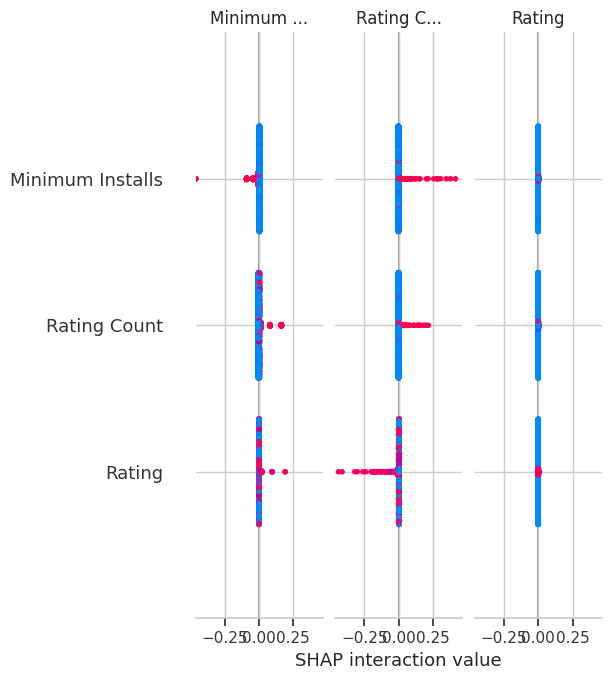

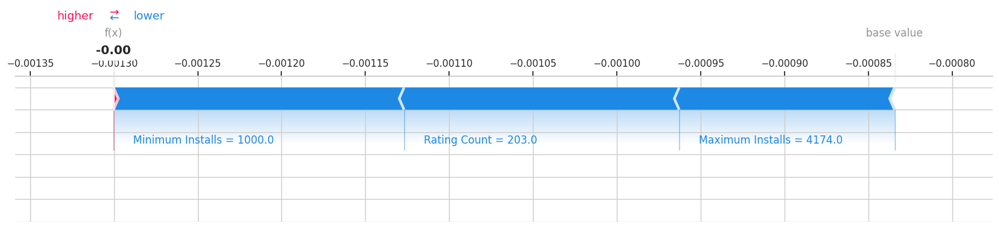

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_2, X_train)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)

sample_idx = 0
class_idx = 0

if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR lr2

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular


feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_2.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)

sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)

exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

macro_f1_rf = f1_score(y_test, y_pred_rf, average='macro')

print(f"--- Random Forest Performance (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_rf:.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))

--- Random Forest Performance (Google Test Set) ---
Macro F1 Score: 0.3553

              precision    recall  f1-score   support

       Cheap       0.54      0.53      0.54      1729
   Expensive       0.16      0.28      0.20       442
         Mid       0.39      0.28      0.33      1097

    accuracy                           0.41      3268
   macro avg       0.36      0.36      0.36      3268
weighted avg       0.44      0.41      0.42      3268



--- Tuned Random Forest Performance (Google Test Set) ---
Macro F1 Score: 0.3708

              precision    recall  f1-score   support

       Cheap       0.57      0.50      0.53      1729
   Expensive       0.18      0.36      0.24       442
         Mid       0.40      0.31      0.35      1097

    accuracy                           0.41      3268
   macro avg       0.38      0.39      0.37      3268
weighted avg       0.46      0.41      0.43      3268



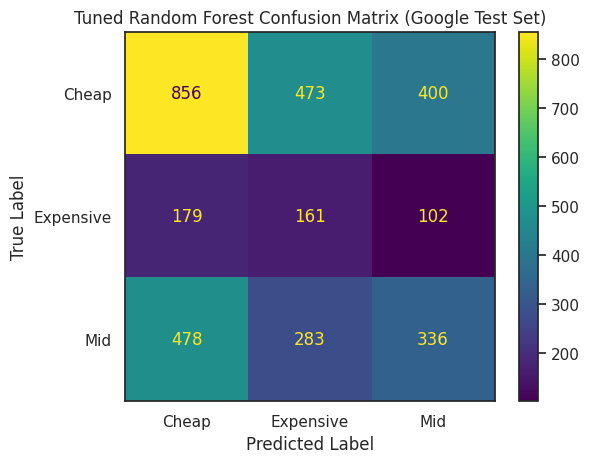

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train, y_train)

y_pred_rf_2 = rf_2.predict(X_test)

macro_f1_rf_2 = f1_score(
    y_test,
    y_pred_rf_2,
    average='macro'
)

print(f"--- Tuned Random Forest Performance (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_rf_2:.4f}\n")

print(
    classification_report(
        y_test,
        y_pred_rf_2,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

cm_rf_2 = confusion_matrix(y_test, y_pred_rf_2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_2,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')

plt.title("Tuned Random Forest Confusion Matrix (Google Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Textual — Same Platform

## Apple x Apple

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, classification_report

text_col = 'text_clean' if 'text_clean' in apple.columns else 'text'

apple_text_df = apple[[text_col, 'Price_Class']].dropna().copy()
X_text = apple_text_df[text_col].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(apple_text_df['Price_Class'])

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_text_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_text_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_text_model.predict(X_test_tfidf)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Textual Logistic Regression (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

--- Textual Logistic Regression (Apple Test Set) ---
Macro F1 Score: 0.5186

              precision    recall  f1-score   support

       Cheap       0.73      0.71      0.72      6698
   Expensive       0.36      0.47      0.41      1670
         Mid       0.46      0.40      0.43      3049

    accuracy                           0.59     11417
   macro avg       0.52      0.53      0.52     11417
weighted avg       0.60      0.59      0.60     11417



TUNING WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_text_model = LogisticRegression(
    C=4.0,
    max_iter=1000,
    class_weight=None,
    random_state=42
)
lr_text_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_text_model.predict(X_test_tfidf)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Textual Logistic Regression (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

--- Textual Logistic Regression (Apple Test Set) ---
Macro F1 Score: 0.5209

              precision    recall  f1-score   support

       Cheap       0.68      0.90      0.77      6698
   Expensive       0.57      0.28      0.37      1670
         Mid       0.57      0.33      0.42      3049

    accuracy                           0.65     11417
   macro avg       0.61      0.50      0.52     11417
weighted avg       0.63      0.65      0.62     11417



--- Textual Linear SVM (Apple Test Set) ---
Macro F1 Score: 0.5288

              precision    recall  f1-score   support

       Cheap       0.71      0.81      0.75      6698
   Expensive       0.42      0.40      0.41      1670
         Mid       0.51      0.36      0.42      3049

    accuracy                           0.63     11417
   macro avg       0.54      0.52      0.53     11417
weighted avg       0.61      0.63      0.62     11417



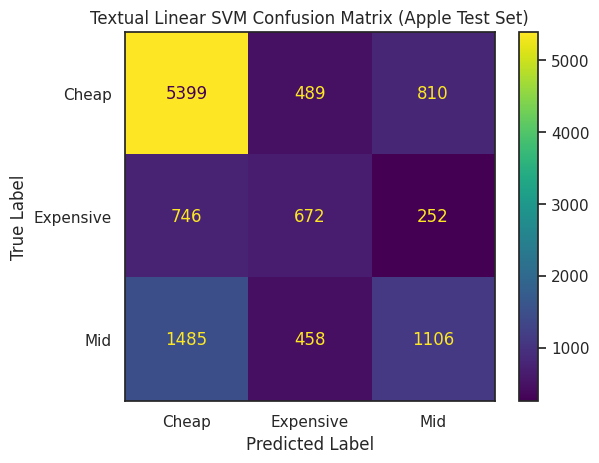

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

svm_text_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)
svm_text_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_text_model.predict(X_test_tfidf)
macro_f1_svm = f1_score(y_test, y_pred_svm, average='macro')

print(f"--- Textual Linear SVM (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_svm:.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))

cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')

plt.title("Textual Linear SVM Confusion Matrix (Apple Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Google x Google

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, classification_report

text_col = 'text_clean' if 'text_clean' in google.columns else ('text' if 'text' in google.columns else 'App Name')
target_col = 'Price_Class'

google_text_df = google[[text_col, target_col]].dropna().copy()
X_text = google_text_df[text_col].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(google_text_df[target_col])

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)

--- Textual Logistic Regression (Google Test Set) ---
Macro F1 Score: 0.5664

              precision    recall  f1-score   support

       Cheap       0.70      0.70      0.70      1729
   Expensive       0.41      0.54      0.46       442
         Mid       0.57      0.50      0.54      1097

    accuracy                           0.61      3268
   macro avg       0.56      0.58      0.57      3268
weighted avg       0.62      0.61      0.61      3268



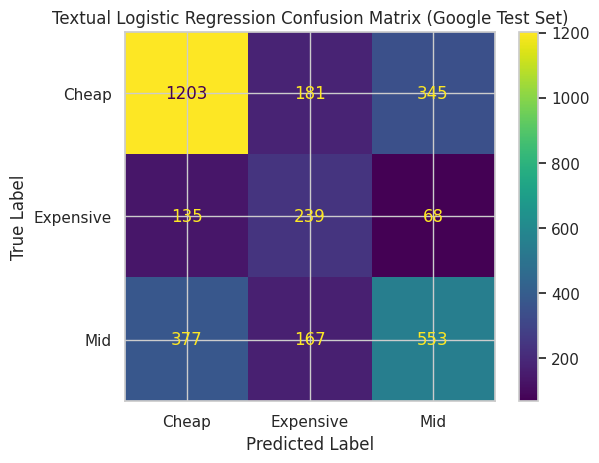

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_text_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_text_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_text_model.predict(X_test_tfidf)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Textual Logistic Regression (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')

plt.title("Textual Logistic Regression Confusion Matrix (Google Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

SHAP AND LIME FOR THE BEST MODEL

In [ ]:
#SHAP FOR LR

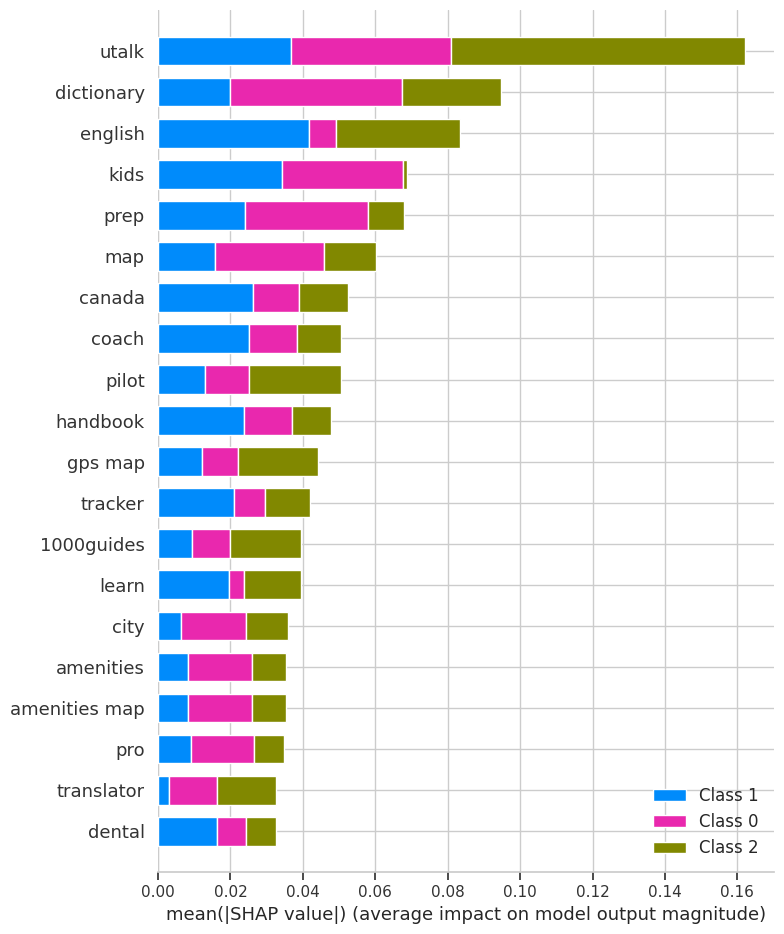

In [ ]:
!pip install shap -q

import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(
    lr_text_model,
    X_train_tfidf
)

X_shap = X_test_tfidf[:100]

shap_values = explainer(X_shap)

feature_names = tfidf_model.get_feature_names_out()


shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=20
)

Text:
abcba pro

Actual class:
Cheap

Predicted class:
Cheap

SHAP shape: (1, 5000, 3)


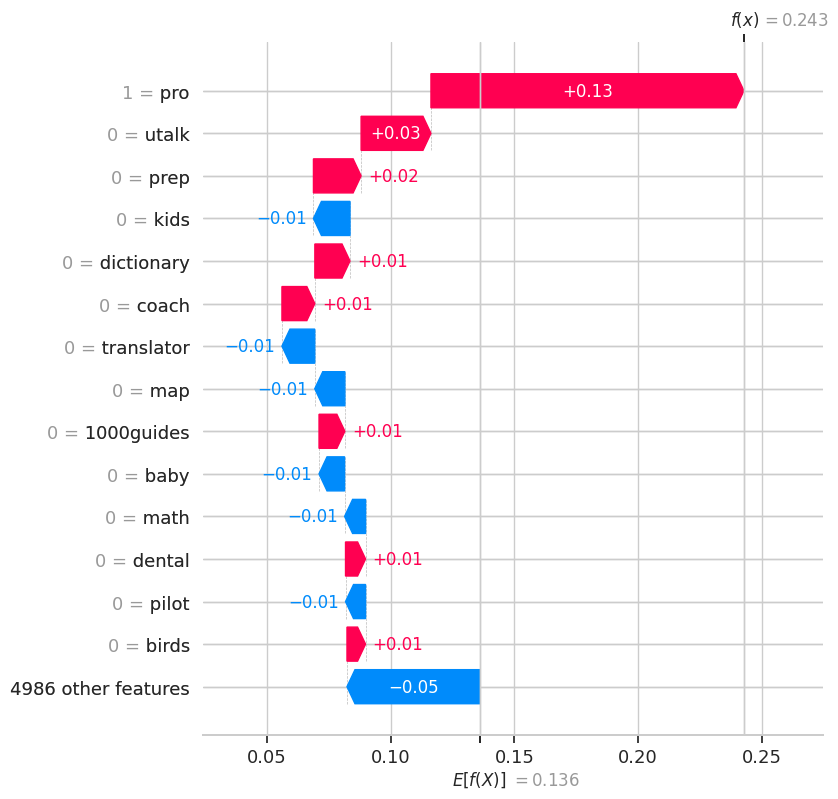

In [ ]:

sample_index = 0

sample_text = X_test_text.iloc[sample_index]
sample_tfidf = X_test_tfidf[sample_index]

print("Text:")
print(sample_text)

print("\nActual class:")
print(label_encoder.inverse_transform([y_test[sample_index]])[0])


predicted_class = lr_text_model.predict(sample_tfidf)[0]

print("\nPredicted class:")
print(label_encoder.inverse_transform([predicted_class])[0])


sample_shap = explainer(sample_tfidf)

print("\nSHAP shape:", sample_shap.shape)



single_class_shap = sample_shap[0, :, predicted_class]


single_class_explanation = shap.Explanation(
    values=single_class_shap,
    base_values=sample_shap.base_values[0, predicted_class],
    data=sample_tfidf.toarray()[0],
    feature_names=tfidf_model.get_feature_names_out()
)


shap.plots.waterfall(
    single_class_explanation,
    max_display=15
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 19.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
from lime.lime_text import LimeTextExplainer


lime_explainer = LimeTextExplainer(
    class_names=label_encoder.classes_
)

def predict_proba(texts):
    texts = pd.Series(texts)


    tfidf_features = tfidf_model.transform(texts)

    return lr_text_model.predict_proba(tfidf_features)

In [ ]:
sample_index = 0

sample_text = X_test_text.iloc[sample_index]

lime_exp = lime_explainer.explain_instance(
    sample_text,
    predict_proba,
    num_features=15,
    num_samples=1000
)

print("Actual class:",
      label_encoder.inverse_transform([y_test[sample_index]])[0])

print("Predicted class:",
      label_encoder.inverse_transform(
          [lr_text_model.predict(
              tfidf_model.transform([sample_text])
          )[0]]
      )[0])

print("\nLIME Explanation:")

for feature, weight in lime_exp.as_list():
    print(f"{feature}: {weight:.4f}")

Actual class: Cheap
Predicted class: Cheap

LIME Explanation:
pro: -0.0166
abcba: 0.0076


In [ ]:
lime_exp.show_in_notebook(text=True)

TUNING WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_text_model = LogisticRegression(
    C=4.5,
    max_iter=1000,
    class_weight= None,
    random_state=42
)
lr_text_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_text_model.predict(X_test_tfidf)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Textual Logistic Regression (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

--- Textual Logistic Regression (Google Test Set) ---
Macro F1 Score: 0.5592

              precision    recall  f1-score   support

       Cheap       0.66      0.80      0.73      1729
   Expensive       0.56      0.34      0.43       442
         Mid       0.58      0.48      0.53      1097

    accuracy                           0.63      3268
   macro avg       0.60      0.54      0.56      3268
weighted avg       0.62      0.63      0.62      3268



In [ ]:
from sklearn.svm import LinearSVC

svm_text_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)
svm_text_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_text_model.predict(X_test_tfidf)
macro_f1_svm = f1_score(y_test, y_pred_svm, average='macro')

print(f"--- Textual Linear SVM (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_svm:.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=label_encoder.classes_))

--- Textual Linear SVM (Google Test Set) ---
Macro F1 Score: 0.5619

              precision    recall  f1-score   support

       Cheap       0.69      0.74      0.71      1729
   Expensive       0.43      0.45      0.44       442
         Mid       0.58      0.50      0.53      1097

    accuracy                           0.62      3268
   macro avg       0.56      0.56      0.56      3268
weighted avg       0.61      0.62      0.61      3268



TUNING WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.svm import LinearSVC

svm_text_model_2 = LinearSVC(
    C=0.2,
    class_weight=None,
    random_state=42,
    max_iter=3000
)

svm_text_model_2.fit(X_train_tfidf, y_train)

y_pred_svm_2 = svm_text_model_2.predict(X_test_tfidf)

macro_f1_svm_2 = f1_score(
    y_test,
    y_pred_svm_2,
    average='macro'
)

print(f"--- Tuned Textual Linear SVM (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_svm_2:.4f}\n")

print(
    classification_report(
        y_test,
        y_pred_svm_2,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

--- Tuned Textual Linear SVM (Google Test Set) ---
Macro F1 Score: 0.5523

              precision    recall  f1-score   support

       Cheap       0.65      0.86      0.74      1729
   Expensive       0.65      0.30      0.41       442
         Mid       0.61      0.44      0.51      1097

    accuracy                           0.64      3268
   macro avg       0.64      0.53      0.55      3268
weighted avg       0.64      0.64      0.62      3268



# Numerical — Cross Platform

## Apple x Google

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report

apple_num = apple.copy()
google_num = google.copy()

apple_num['Rating'] = apple_num['Average_User_Rating']
apple_num['Rating_Count'] = apple_num['Reviews']
apple_num['Free'] = apple_num['Free'].astype(int)

google_num['Rating_Count'] = google_num['Rating Count'] if 'Rating Count' in google_num.columns else google_num['Rating_Count']
google_num['Free'] = google_num['Free'].astype(int)

num_features = ['Rating', 'Rating_Count', 'Free']

common_price_classes = sorted(list(set(apple_num['Price_Class']).intersection(set(google_num['Price_Class']))))

apple_filtered = apple_num[apple_num['Price_Class'].isin(common_price_classes)].dropna(subset=num_features + ['Price_Class']).copy()
google_filtered = google_num[google_num['Price_Class'].isin(common_price_classes)].dropna(subset=num_features + ['Price_Class']).copy()

label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(apple_filtered['Price_Class'])
y_test = label_encoder.transform(google_filtered['Price_Class'])

X_train = apple_filtered[num_features]
X_test = google_filtered[num_features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
print(f"--- Logistic Regression (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Logistic Regression (Cross-Platform Numerical) ---
Macro F1 Score: 0.2177

              precision    recall  f1-score   support

       Cheap       0.54      0.01      0.01      8646
   Expensive       0.13      0.50      0.21      2209
         Mid       0.36      0.52      0.43      5483

    accuracy                           0.25     16338
   macro avg       0.35      0.34      0.22     16338
weighted avg       0.43      0.25      0.18     16338



In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

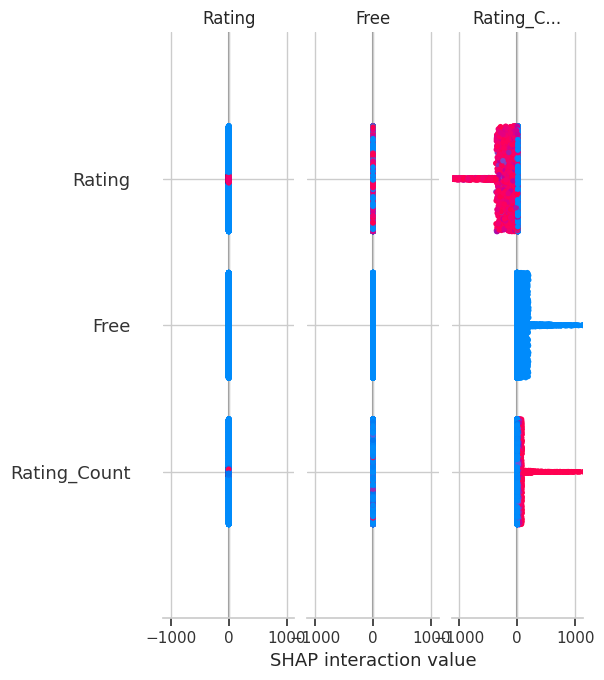

/usr/local/lib/python3.13/dist-packages/shap/plots/_force_matplotlib.py:107: RuntimeWarning: divide by zero encountered in scalar divide
  feature_contribution = np.abs(float(feature[0]) - pre_val) / np.abs(total_effect)


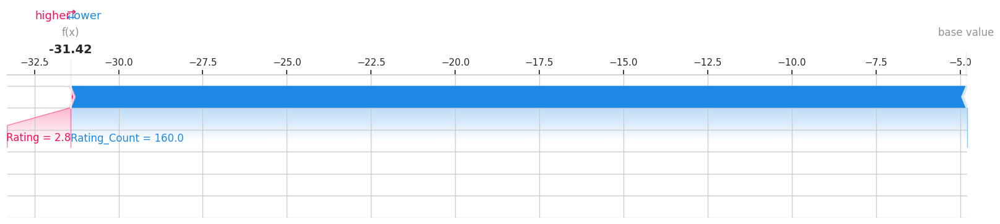

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)

sample_idx = 0
class_idx = 0


if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular


feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)


sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)


exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

TUNING WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=3.0,
    max_iter=1000,
    class_weight=None,
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
print(f"--- Logistic Regression (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Logistic Regression (Cross-Platform Numerical) ---
Macro F1 Score: 0.2420

              precision    recall  f1-score   support

       Cheap       0.53      0.99      0.69      8646
   Expensive       0.00      0.00      0.00      2209
         Mid       0.60      0.02      0.03      5483

    accuracy                           0.53     16338
   macro avg       0.38      0.34      0.24     16338
weighted avg       0.48      0.53      0.38     16338



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

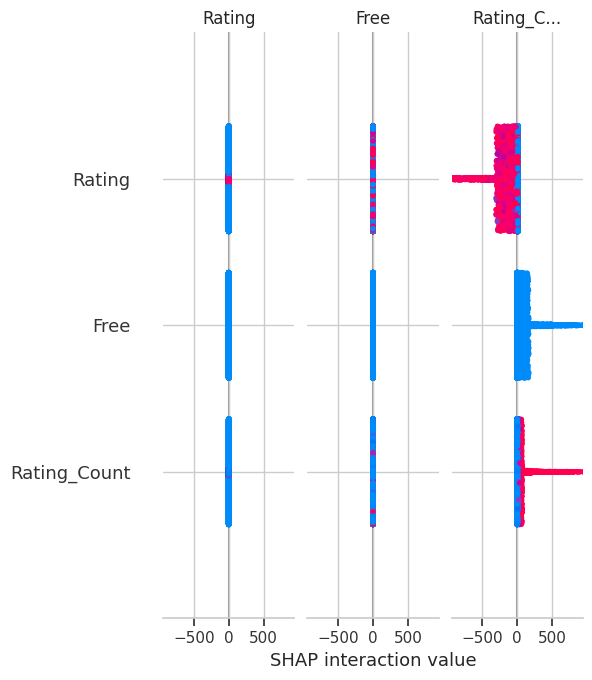

/usr/local/lib/python3.13/dist-packages/shap/plots/_force_matplotlib.py:107: RuntimeWarning: divide by zero encountered in scalar divide
  feature_contribution = np.abs(float(feature[0]) - pre_val) / np.abs(total_effect)


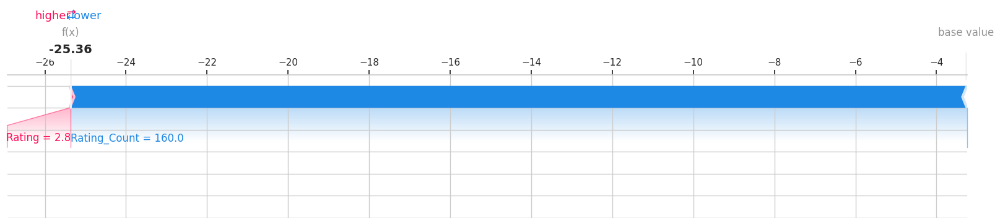

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)


sample_idx = 0
class_idx = 0

if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular


feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)


sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)

exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
print(f"--- Random Forest (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_rf, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=common_price_classes))

--- Random Forest (Cross-Platform Numerical) ---
Macro F1 Score: 0.2682

              precision    recall  f1-score   support

       Cheap       0.51      0.25      0.33      8646
   Expensive       0.13      0.57      0.22      2209
         Mid       0.37      0.19      0.25      5483

    accuracy                           0.27     16338
   macro avg       0.34      0.34      0.27     16338
weighted avg       0.41      0.27      0.29     16338



--- XGBoost (Cross-Platform Numerical) ---
Macro F1 Score: 0.2655

              precision    recall  f1-score   support

       Cheap       0.54      0.97      0.69      8646
   Expensive       0.00      0.00      0.00      2209
         Mid       0.47      0.06      0.11      5483

    accuracy                           0.53     16338
   macro avg       0.33      0.34      0.27     16338
weighted avg       0.44      0.53      0.40     16338



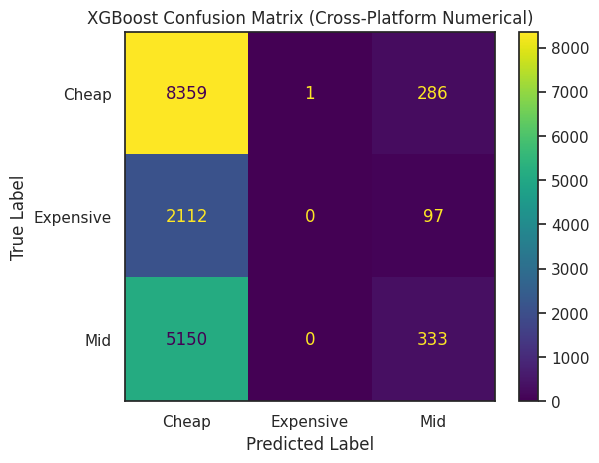

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
print(f"--- XGBoost (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_xgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=common_price_classes))

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=common_price_classes
)

disp.plot(values_format='d')

plt.title("XGBoost Confusion Matrix (Cross-Platform Numerical)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
print(f"--- Support Vector Machine (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Support Vector Machine (Cross-Platform Numerical) ---
Macro F1 Score: 0.2465

              precision    recall  f1-score   support

       Cheap       0.53      0.99      0.69      8646
   Expensive       0.00      0.00      0.00      2209
         Mid       0.52      0.02      0.05      5483

    accuracy                           0.53     16338
   macro avg       0.35      0.34      0.25     16338
weighted avg       0.46      0.53      0.38     16338



In [ ]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_test)
print(f"--- LightGBM (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lgb, target_names=common_price_classes))

--- LightGBM (Cross-Platform Numerical) ---
Macro F1 Score: 0.2706

              precision    recall  f1-score   support

       Cheap       0.54      0.96      0.69      8646
   Expensive       0.21      0.00      0.00      2209
         Mid       0.46      0.07      0.12      5483

    accuracy                           0.53     16338
   macro avg       0.40      0.34      0.27     16338
weighted avg       0.47      0.53      0.40     16338



In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_model.fit(X_train_scaled, y_train)

y_pred_mlp = mlp_model.predict(X_test_scaled)
print(f"--- Multi-Layer Perceptron (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mlp, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mlp, target_names=common_price_classes))

--- Multi-Layer Perceptron (Cross-Platform Numerical) ---
Macro F1 Score: 0.2505

              precision    recall  f1-score   support

       Cheap       0.53      0.99      0.69      8646
   Expensive       0.00      0.00      0.00      2209
         Mid       0.52      0.03      0.06      5483

    accuracy                           0.53     16338
   macro avg       0.35      0.34      0.25     16338
weighted avg       0.46      0.53      0.39     16338



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


TUNING WITH TENSORFLOW KERAS

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score, classification_report

tf.random.set_seed(42)


keras_mlp = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),


    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.30),


    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.25),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.20),


    layers.Dense(32, activation='relu'),
    layers.Dropout(0.15),


    layers.Dense(len(common_price_classes), activation='softmax')
])

keras_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)


history = keras_mlp.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


y_pred_prob = keras_mlp.predict(X_test_scaled)
y_pred_keras = y_pred_prob.argmax(axis=1)


macro_f1_keras = f1_score(
    y_test,
    y_pred_keras,
    average='macro'
)

print(f"--- Tuned Deep Neural Network (Cross-Platform Numerical) ---")
print(f"Macro F1 Score: {macro_f1_keras:.4f}\n")

print(
    classification_report(
        y_test,
        y_pred_keras,
        target_names=common_price_classes,
        zero_division=0
    )
)

Epoch 1/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.5484 - loss: 1.0208 - val_accuracy: 0.5864 - val_loss: 0.9368
Epoch 2/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5864 - loss: 0.9584 - val_accuracy: 0.5860 - val_loss: 0.9384
Epoch 3/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5870 - loss: 0.9522 - val_accuracy: 0.5860 - val_loss: 0.9384
Epoch 4/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5872 - loss: 0.9493 - val_accuracy: 0.5860 - val_loss: 0.9357
Epoch 5/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5868 - loss: 0.9481 - val_accuracy: 0.5860 - val_loss: 0.9356
Epoch 6/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5870 - loss: 0.9473 - val_accuracy: 0.5861 - val_loss: 0.9356
Epoch 7/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5871 - loss: 0.9465 - val_accuracy: 0.5859 - val_loss: 0.9334
Epoch 8/150
714/714 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5871 - loss: 0.9466 - val_acc

## Google x Apple

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report

google_num = google.copy()
apple_num = apple.copy()

google_num['Rating_Count'] = google_num['Rating Count'] if 'Rating Count' in google_num.columns else google_num['Rating_Count']
google_num['Free'] = google_num['Free'].astype(int)

apple_num['Rating'] = apple_num['Average_User_Rating']
apple_num['Rating_Count'] = apple_num['Reviews']
apple_num['Free'] = apple_num['Free'].astype(int)

num_features = ['Rating', 'Rating_Count', 'Free']

common_price_classes = sorted(list(set(google_num['Price_Class']).intersection(set(apple_num['Price_Class']))))

google_filtered = google_num[google_num['Price_Class'].isin(common_price_classes)].dropna(subset=num_features + ['Price_Class']).copy()
apple_filtered = apple_num[apple_num['Price_Class'].isin(common_price_classes)].dropna(subset=num_features + ['Price_Class']).copy()

label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(google_filtered['Price_Class'])
y_test = label_encoder.transform(apple_filtered['Price_Class'])

X_train = google_filtered[num_features]
X_test = apple_filtered[num_features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
print(f"--- Logistic Regression (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Logistic Regression (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2479

              precision    recall  f1-score   support

       Cheap       0.59      1.00      0.74     33488
   Expensive       0.00      0.00      0.00      8352
         Mid       0.54      0.00      0.00     15242

    accuracy                           0.59     57082
   macro avg       0.37      0.33      0.25     57082
weighted avg       0.49      0.59      0.43     57082



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#SHAP FOR LR

<Figure size 1000x600 with 0 Axes>

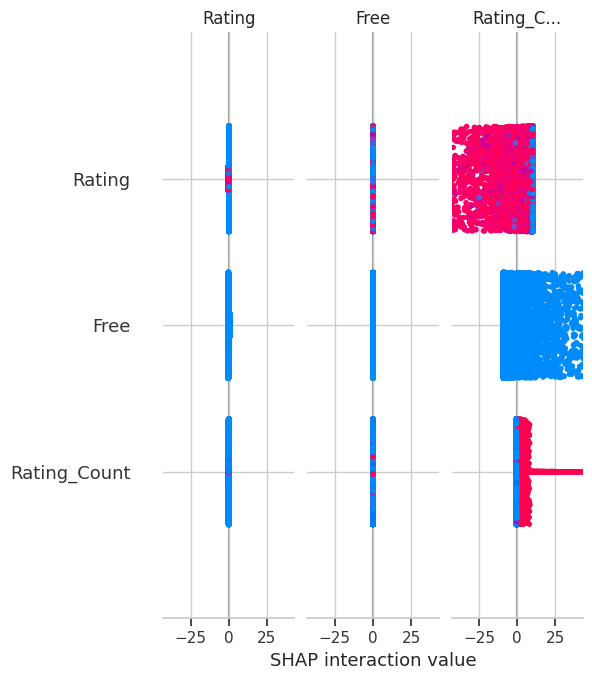

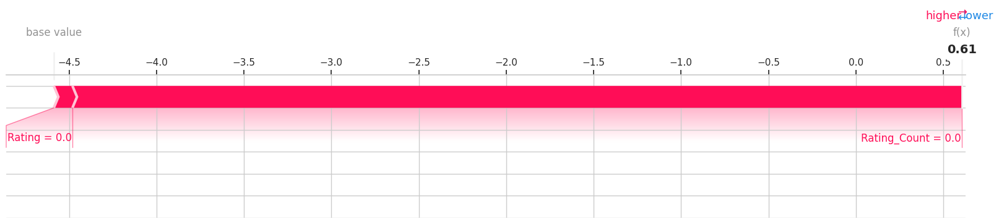

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


explainer = shap.LinearExplainer(lr_model, X_train)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test)


sample_idx = 0
class_idx = 0


if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = explainer.expected_value[class_idx]
else:
    base_val = explainer.expected_value


if isinstance(shap_values, list):
    sample_shap = shap_values[class_idx][sample_idx]
elif shap_values.ndim == 3:
    sample_shap = shap_values[sample_idx, :, class_idx]
else:
    sample_shap = shap_values[sample_idx]

shap.initjs()
shap.force_plot(
    base_val,
    sample_shap,
    X_test.iloc[sample_idx],
    matplotlib=True
)

In [ ]:
#LIME FOR LR

In [ ]:
!pip install lime -q

import lime
import lime.lime_tabular


feature_names = list(X_train.columns)
class_names = [str(c) for c in lr_model.classes_]

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)


sample_idx = 0

exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_idx],
    predict_fn=lr_model.predict_proba,
    num_features=len(feature_names)
)


exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
print(f"--- Random Forest (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_rf, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=common_price_classes))

--- Random Forest (Train: Google, Test: Apple) ---
Macro F1 Score: 0.3117

              precision    recall  f1-score   support

       Cheap       0.57      0.60      0.58     33488
   Expensive       0.14      0.04      0.07      8352
         Mid       0.26      0.32      0.29     15242

    accuracy                           0.44     57082
   macro avg       0.32      0.32      0.31     57082
weighted avg       0.42      0.44      0.43     57082



In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
print(f"--- XGBoost (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_xgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=common_price_classes))

--- XGBoost (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2625

              precision    recall  f1-score   support

       Cheap       0.59      0.99      0.74     33488
   Expensive       0.29      0.00      0.00      8352
         Mid       0.38      0.03      0.05     15242

    accuracy                           0.59     57082
   macro avg       0.42      0.34      0.26     57082
weighted avg       0.49      0.59      0.45     57082



In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
print(f"--- Support Vector Machine (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Support Vector Machine (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2523

              precision    recall  f1-score   support

       Cheap       0.59      1.00      0.74     33488
   Expensive       0.00      0.00      0.00      8352
         Mid       0.45      0.01      0.02     15242

    accuracy                           0.59     57082
   macro avg       0.35      0.34      0.25     57082
weighted avg       0.47      0.59      0.44     57082



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


--- LightGBM (Train: Google, Test: Apple) ---
Macro F1 Score: 0.3230

              precision    recall  f1-score   support

       Cheap       0.59      0.77      0.67     33488
   Expensive       0.14      0.08      0.10      8352
         Mid       0.28      0.16      0.20     15242

    accuracy                           0.50     57082
   macro avg       0.34      0.34      0.32     57082
weighted avg       0.44      0.50      0.46     57082



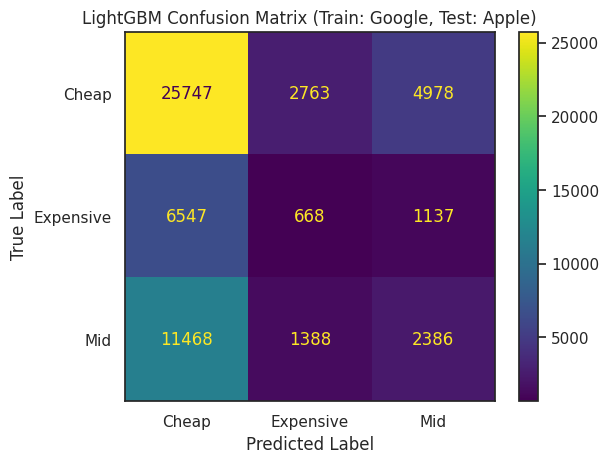

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lgb_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_test)
print(f"--- LightGBM (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lgb, target_names=common_price_classes))

cm_lgb = confusion_matrix(y_test, y_pred_lgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgb,
    display_labels=common_price_classes
)

disp.plot(values_format='d')

plt.title("LightGBM Confusion Matrix (Train: Google, Test: Apple)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_model.fit(X_train_scaled, y_train)

y_pred_mlp = mlp_model.predict(X_test_scaled)
print(f"--- Multi-Layer Perceptron (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mlp, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mlp, target_names=common_price_classes))

--- Multi-Layer Perceptron (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2536

              precision    recall  f1-score   support

       Cheap       0.59      1.00      0.74     33488
   Expensive       0.00      0.00      0.00      8352
         Mid       0.45      0.01      0.02     15242

    accuracy                           0.59     57082
   macro avg       0.35      0.34      0.25     57082
weighted avg       0.47      0.59      0.44     57082



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Textual — Cross Platform

## Apple x Google


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

apple_text_col = 'text_clean' if 'text_clean' in apple.columns else ('text' if 'text' in apple.columns else 'App_Name')
google_text_col = 'text_clean' if 'text_clean' in google.columns else ('text' if 'text' in google.columns else 'App Name')

apple_df = apple[[apple_text_col, 'Price_Class']].dropna().copy()
google_df = google[[google_text_col, 'Price_Class']].dropna().copy()

apple_df.columns = ['text', 'Price_Class']
google_df.columns = ['text', 'Price_Class']

common_price_classes = sorted(list(set(apple_df['Price_Class']).intersection(set(google_df['Price_Class']))))

apple_filtered = apple_df[apple_df['Price_Class'].isin(common_price_classes)].copy()
google_filtered = google_df[google_df['Price_Class'].isin(common_price_classes)].copy()

label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(apple_filtered['Price_Class'])
y_test = label_encoder.transform(google_filtered['Price_Class'])

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(
    apple_filtered['text'], google_filtered['text']
)

max_len = 30
tokenizer = Tokenizer(char_level=True, lower=True, oov_token='<UNK>')
tokenizer.fit_on_texts(apple_filtered['text'].astype(str))

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(apple_filtered['text'].astype(str)), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(google_filtered['text'].astype(str)), maxlen=max_len, padding='post', truncating='post')

vocab_size = len(tokenizer.word_index) + 1
num_classes = len(common_price_classes)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)
print(f"--- Textual Logistic Regression (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Textual Logistic Regression (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4042

              precision    recall  f1-score   support

       Cheap       0.57      0.90      0.70      8646
   Expensive       0.46      0.15      0.23      2209
         Mid       0.53      0.19      0.28      5483

    accuracy                           0.56     16338
   macro avg       0.52      0.42      0.40     16338
weighted avg       0.54      0.56      0.50     16338



TUNING WITH REGULARIZATION STRENGTH

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=5.6,
    max_iter=1000,
    class_weight=None,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)
print(f"--- Textual Logistic Regression (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Textual Logistic Regression (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4234

              precision    recall  f1-score   support

       Cheap       0.58      0.87      0.70      8646
   Expensive       0.41      0.20      0.26      2209
         Mid       0.51      0.22      0.31      5483

    accuracy                           0.56     16338
   macro avg       0.50      0.43      0.42     16338
weighted avg       0.53      0.56      0.51     16338



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)
print(f"--- Textual Linear SVM (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Textual Linear SVM (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4201

              precision    recall  f1-score   support

       Cheap       0.58      0.88      0.70      8646
   Expensive       0.44      0.19      0.26      2209
         Mid       0.52      0.21      0.30      5483

    accuracy                           0.56     16338
   macro avg       0.51      0.43      0.42     16338
weighted avg       0.54      0.56      0.51     16338



TUNING WITH C

In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=4.5,
    class_weight=None,
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)
print(f"--- Textual Linear SVM (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Textual Linear SVM (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4240

              precision    recall  f1-score   support

       Cheap       0.58      0.87      0.70      8646
   Expensive       0.42      0.19      0.27      2209
         Mid       0.50      0.22      0.31      5483

    accuracy                           0.56     16338
   macro avg       0.50      0.43      0.42     16338
weighted avg       0.53      0.56      0.51     16338



In [ ]:
from sklearn.naive_bayes import MultinomialNB

mnb_model = MultinomialNB(alpha=0.1)
mnb_model.fit(X_train_tfidf, y_train)

y_pred_mnb = mnb_model.predict(X_test_tfidf)
print(f"--- Textual Multinomial Naive Bayes (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mnb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mnb, target_names=common_price_classes))

--- Textual Multinomial Naive Bayes (Train: Apple, Test: Google) ---
Macro F1 Score: 0.3982

              precision    recall  f1-score   support

       Cheap       0.57      0.89      0.69      8646
   Expensive       0.39      0.17      0.23      2209
         Mid       0.50      0.18      0.27      5483

    accuracy                           0.55     16338
   macro avg       0.49      0.41      0.40     16338
weighted avg       0.52      0.55      0.49     16338



--- Textual Complement Naive Bayes (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4302

              precision    recall  f1-score   support

       Cheap       0.61      0.66      0.63      8646
   Expensive       0.24      0.37      0.30      2209
         Mid       0.45      0.30      0.36      5483

    accuracy                           0.50     16338
   macro avg       0.44      0.44      0.43     16338
weighted avg       0.51      0.50      0.50     16338



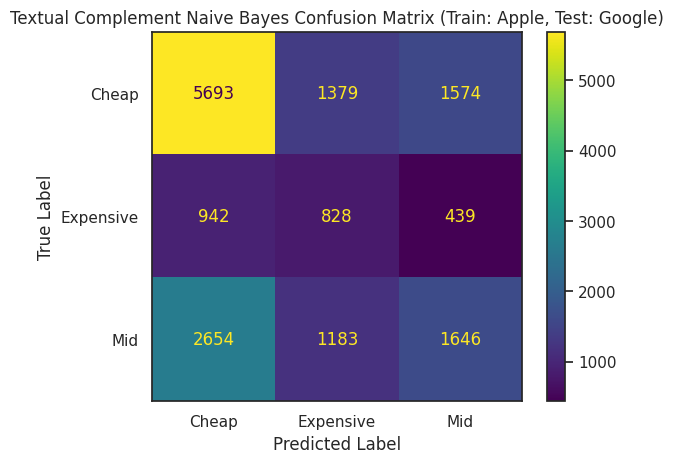

In [ ]:
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cnb_model = ComplementNB(alpha=0.1)
cnb_model.fit(X_train_tfidf, y_train)

y_pred_cnb = cnb_model.predict(X_test_tfidf)
print(f"--- Textual Complement Naive Bayes (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_cnb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_cnb, target_names=common_price_classes))

cm_cnb = confusion_matrix(y_test, y_pred_cnb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnb,
    display_labels=common_price_classes
)

disp.plot(values_format='d')

plt.title("Textual Complement Naive Bayes Confusion Matrix (Train: Apple, Test: Google)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

bilstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    Bidirectional(LSTM(units=64, dropout=0.2, recurrent_dropout=0.2)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(units=num_classes, activation='softmax')
])

bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

bilstm_model.fit(
    X_train_seq, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_bilstm = np.argmax(bilstm_model.predict(X_test_seq), axis=1)
print(f"--- Textual BiLSTM (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_bilstm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_bilstm, target_names=common_price_classes))

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1517/1517 ━━━━━━━━━━━━━━━━━━━━ 158s 99ms/step - accuracy: 0.5821 - loss: 0.9507 - val_accuracy: 0.6135 - val_loss: 0.9158
Epoch 2/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 140s 93ms/step - accuracy: 0.5850 - loss: 0.9403 - val_accuracy: 0.6146 - val_loss: 0.9076
Epoch 3/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 139s 91ms/step - accuracy: 0.5891 - loss: 0.9343 - val_accuracy: 0.6222 - val_loss: 0.8983
Epoch 4/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 147s 97ms/step - accuracy: 0.5956 - loss: 0.9245 - val_accuracy: 0.6274 - val_loss: 0.8907
Epoch 5/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 192s 91ms/step - accuracy: 0.6041 - loss: 0.9135 - val_accuracy: 0.6279 - val_loss: 0.8864
Epoch 6/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 135s 89ms/step - accuracy: 0.6092 - loss: 0.9016 - val_accuracy: 0.6285 - val_loss: 0.8836
Epoch 7/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 155s 97ms/step - accuracy: 0.6133 - loss: 0.8930 - val_accuracy: 0.6264 - val_loss: 0.8838
Epoch 8/25
1517/1517 ━━━━━━━━━━━━━━━━━━━━ 136s 90ms/step - accuracy: 0.6179 - lo

In [ ]:
from tensorflow.keras.layers import GRU

gru_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    GRU(units=64, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.45),
    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

gru_model.fit(
    X_train_seq, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_gru = np.argmax(gru_model.predict(X_test_seq), axis=1)
print(f"--- Textual GRU (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_gru, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_gru, target_names=common_price_classes))

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


759/759 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - accuracy: 0.5810 - loss: 0.9607 - val_accuracy: 0.6135 - val_loss: 0.9115
Epoch 2/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.5824 - loss: 0.9528 - val_accuracy: 0.6133 - val_loss: 0.9177
Epoch 3/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 42s 52ms/step - accuracy: 0.5828 - loss: 0.9459 - val_accuracy: 0.6146 - val_loss: 0.9001
Epoch 4/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 37s 49ms/step - accuracy: 0.5862 - loss: 0.9367 - val_accuracy: 0.6242 - val_loss: 0.8919
Epoch 5/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.5928 - loss: 0.9291 - val_accuracy: 0.6291 - val_loss: 0.8870
Epoch 6/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.6014 - loss: 0.9183 - val_accuracy: 0.6300 - val_loss: 0.8831
Epoch 7/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.6058 - loss: 0.9108 - val_accuracy: 0.6360 - val_loss: 0.8725
Epoch 8/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.6103 - loss: 0.9018 - val_accurac

## Google x Apple

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

google_text_col = 'text_clean' if 'text_clean' in google.columns else ('text' if 'text' in google.columns else 'App Name')
apple_text_col = 'text_clean' if 'text_clean' in apple.columns else ('text' if 'text' in apple.columns else 'App_Name')

google_df = google[[google_text_col, 'Price_Class']].dropna().copy()
apple_df = apple[[apple_text_col, 'Price_Class']].dropna().copy()

google_df.columns = ['text', 'Price_Class']
apple_df.columns = ['text', 'Price_Class']

common_price_classes = sorted(list(set(google_df['Price_Class']).intersection(set(apple_df['Price_Class']))))

google_filtered = google_df[google_df['Price_Class'].isin(common_price_classes)].copy()
apple_filtered = apple_df[apple_df['Price_Class'].isin(common_price_classes)].copy()

label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(google_filtered['Price_Class'])
y_test = label_encoder.transform(apple_filtered['Price_Class'])

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(
    google_filtered['text'], apple_filtered['text']
)

max_len = 30
tokenizer = Tokenizer(char_level=True, lower=True, oov_token='<UNK>')
tokenizer.fit_on_texts(google_filtered['text'].astype(str))

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(google_filtered['text'].astype(str)), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(apple_filtered['text'].astype(str)), maxlen=max_len, padding='post', truncating='post')

vocab_size = len(tokenizer.word_index) + 1
num_classes = len(common_price_classes)

--- Textual Logistic Regression (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4147

              precision    recall  f1-score   support

       Cheap       0.64      0.67      0.66     33488
   Expensive       0.25      0.27      0.26      8352
         Mid       0.35      0.30      0.32     15242

    accuracy                           0.51     57082
   macro avg       0.42      0.42      0.41     57082
weighted avg       0.51      0.51      0.51     57082



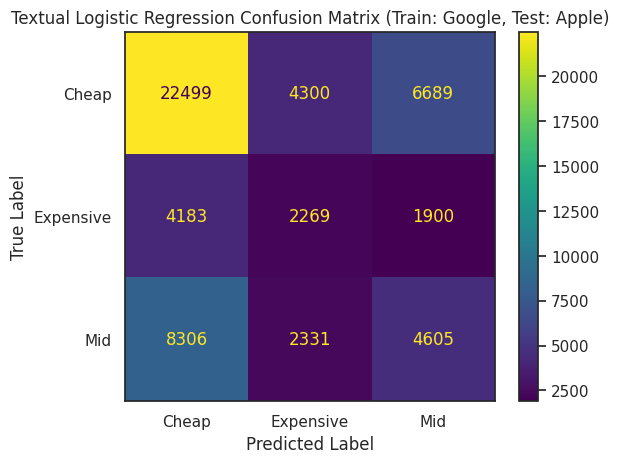

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)
print(f"--- Textual Logistic Regression (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=common_price_classes
)

disp.plot(values_format='d')

plt.title("Textual Logistic Regression Confusion Matrix (Train: Google, Test: Apple)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

TUNING WITH C

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=5.0,
    max_iter=1000,
    class_weight=None,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)
print(f"--- Textual Logistic Regression (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Textual Logistic Regression (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4049

              precision    recall  f1-score   support

       Cheap       0.63      0.79      0.70     33488
   Expensive       0.37      0.13      0.20      8352
         Mid       0.36      0.29      0.32     15242

    accuracy                           0.56     57082
   macro avg       0.45      0.40      0.40     57082
weighted avg       0.52      0.56      0.52     57082



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)
print(f"--- Textual Linear SVM (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Textual Linear SVM (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4132

              precision    recall  f1-score   support

       Cheap       0.64      0.72      0.68     33488
   Expensive       0.28      0.22      0.25      8352
         Mid       0.35      0.29      0.31     15242

    accuracy                           0.53     57082
   macro avg       0.42      0.41      0.41     57082
weighted avg       0.51      0.53      0.52     57082



TUNING

In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=2.5,
    class_weight=None,
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)
print(f"--- Textual Linear SVM (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Textual Linear SVM (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4079

              precision    recall  f1-score   support

       Cheap       0.63      0.77      0.69     33488
   Expensive       0.35      0.16      0.22      8352
         Mid       0.35      0.28      0.31     15242

    accuracy                           0.55     57082
   macro avg       0.44      0.40      0.41     57082
weighted avg       0.51      0.55      0.52     57082



In [ ]:
from sklearn.naive_bayes import MultinomialNB

mnb_model = MultinomialNB(alpha=0.1)
mnb_model.fit(X_train_tfidf, y_train)

y_pred_mnb = mnb_model.predict(X_test_tfidf)
print(f"--- Textual Multinomial Naive Bayes (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mnb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mnb, target_names=common_price_classes))

--- Textual Multinomial Naive Bayes (Train: Google, Test: Apple) ---
Macro F1 Score: 0.3921

              precision    recall  f1-score   support

       Cheap       0.63      0.83      0.71     33488
   Expensive       0.36      0.10      0.16      8352
         Mid       0.37      0.26      0.30     15242

    accuracy                           0.57     57082
   macro avg       0.45      0.40      0.39     57082
weighted avg       0.52      0.57      0.52     57082



In [ ]:
from sklearn.naive_bayes import ComplementNB

cnb_model = ComplementNB(alpha=0.2)
cnb_model.fit(X_train_tfidf, y_train)

y_pred_cnb = cnb_model.predict(X_test_tfidf)
print(f"--- Textual Complement Naive Bayes (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_cnb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_cnb, target_names=common_price_classes))

--- Textual Complement Naive Bayes (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4093

              precision    recall  f1-score   support

       Cheap       0.64      0.69      0.67     33488
   Expensive       0.25      0.22      0.23      8352
         Mid       0.35      0.31      0.33     15242

    accuracy                           0.52     57082
   macro avg       0.41      0.41      0.41     57082
weighted avg       0.51      0.52      0.51     57082



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

bilstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    Bidirectional(LSTM(units=64, dropout=0.2, recurrent_dropout=0.2)),
    Dense(64, activation='relu'),
    Dropout(0.45),
    Dense(units=num_classes, activation='softmax')
])

bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

bilstm_model.fit(
    X_train_seq, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_bilstm = np.argmax(bilstm_model.predict(X_test_seq), axis=1)
print(f"--- Textual BiLSTM (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_bilstm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_bilstm, target_names=common_price_classes))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
217/217 ━━━━━━━━━━━━━━━━━━━━ 43s 105ms/step - accuracy: 0.5273 - loss: 0.9823 - val_accuracy: 0.5296 - val_loss: 0.9799
Epoch 2/5
217/217 ━━━━━━━━━━━━━━━━━━━━ 40s 101ms/step - accuracy: 0.5288 - loss: 0.9708 - val_accuracy: 0.5296 - val_loss: 0.9769
Epoch 3/5
217/217 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - accuracy: 0.5303 - loss: 0.9654 - val_accuracy: 0.5365 - val_loss: 0.9746
Epoch 4/5
217/217 ━━━━━━━━━━━━━━━━━━━━ 21s 97ms/step - accuracy: 0.5346 - loss: 0.9608 - val_accuracy: 0.5251 - val_loss: 0.9714
Epoch 5/5
217/217 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.5368 - loss: 0.9560 - val_accuracy: 0.5235 - val_loss: 0.9726
1784/1784 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step
--- Textual BiLSTM (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2766

              precision    recall  f1-score   support

       Cheap       0.59      0.94      0.72     33488
   Expensive       0.26      0.00      0.01      8352
         Mid       0.27      0.06      0.10     15242

    accuracy 

In [ ]:
from tensorflow.keras.layers import GRU

gru_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    GRU(units=64, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

gru_model.fit(
    X_train_seq, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_gru = np.argmax(gru_model.predict(X_test_seq), axis=1)
print(f"--- Textual GRU (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_gru, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_gru, target_names=common_price_classes))

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


434/434 ━━━━━━━━━━━━━━━━━━━━ 26s 50ms/step - accuracy: 0.5249 - loss: 0.9799 - val_accuracy: 0.5296 - val_loss: 0.9807
Epoch 2/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 39s 45ms/step - accuracy: 0.5291 - loss: 0.9738 - val_accuracy: 0.5296 - val_loss: 0.9799
Epoch 3/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 21s 46ms/step - accuracy: 0.5296 - loss: 0.9722 - val_accuracy: 0.5288 - val_loss: 0.9797
Epoch 4/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.5296 - loss: 0.9685 - val_accuracy: 0.5292 - val_loss: 0.9785
Epoch 5/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - accuracy: 0.5303 - loss: 0.9682 - val_accuracy: 0.5279 - val_loss: 0.9789
Epoch 6/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.5292 - loss: 0.9648 - val_accuracy: 0.5279 - val_loss: 0.9765
Epoch 7/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 39s 44ms/step - accuracy: 0.5303 - loss: 0.9636 - val_accuracy: 0.5288 - val_loss: 0.9735
Epoch 8/10
434/434 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.5328 - loss: 0.9590 - val_accurac

# Multimodal

## Apple x Apple

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report

text_col = 'text_clean' if 'text_clean' in apple.columns else ('text' if 'text' in apple.columns else 'App_Name')
target_col = 'Price_Class'

apple_combined = apple.copy()
apple_combined['Rating'] = apple_combined['Average_User_Rating']
apple_combined['Rating_Count'] = apple_combined['Reviews']
apple_combined['Free'] = apple_combined['Free'].astype(int)

num_cols = ['Rating', 'Rating_Count', 'Free']
if 'Size_Bytes' in apple_combined.columns:
    num_cols.append('Size_Bytes')

apple_combined = apple_combined.dropna(subset=[text_col, target_col] + num_cols).copy()

X_text = apple_combined[text_col].astype(str)
X_num = apple_combined[num_cols].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(apple_combined[target_col])

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text, X_num, y, test_size=0.2, random_state=42, stratify=y
)


X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)

scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)


X_train_combined = hstack([X_train_num_scaled, X_train_tfidf]).tocsr()
X_test_combined = hstack([X_test_num_scaled, X_test_tfidf]).tocsr()

--- Combined Logistic Regression (Apple Test Set) ---
Macro F1 Score: 0.5213

              precision    recall  f1-score   support

       Cheap       0.68      0.93      0.78      6698
   Expensive       0.66      0.26      0.37      1670
         Mid       0.61      0.31      0.41      3049

    accuracy                           0.67     11417
   macro avg       0.65      0.50      0.52     11417
weighted avg       0.66      0.67      0.62     11417



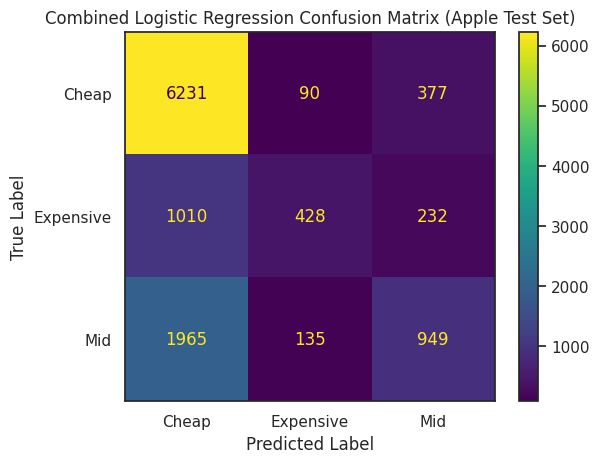

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_combined_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_combined_model.fit(X_train_combined, y_train)


y_pred_lr = lr_combined_model.predict(X_test_combined)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Combined Logistic Regression (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')

plt.title("Combined Logistic Regression Confusion Matrix (Apple Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from xgboost import XGBClassifier


xgb_combined_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_combined_model.fit(X_train_combined, y_train)


y_pred_xgb = xgb_combined_model.predict(X_test_combined)
macro_f1_xgb = f1_score(y_test, y_pred_xgb, average='macro')

print(f"--- Combined XGBoost (Apple Test Set) ---")
print(f"Macro F1 Score: {macro_f1_xgb:.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=label_encoder.classes_))

--- Combined XGBoost (Apple Test Set) ---
Macro F1 Score: 0.4058

              precision    recall  f1-score   support

       Cheap       0.63      0.99      0.77      6698
   Expensive       0.82      0.10      0.18      1670
         Mid       0.76      0.17      0.27      3049

    accuracy                           0.64     11417
   macro avg       0.73      0.42      0.41     11417
weighted avg       0.69      0.64      0.55     11417



## Google x Google

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report


text_col = 'text_clean' if 'text_clean' in google.columns else ('text' if 'text' in google.columns else 'App Name')
target_col = 'Price_Class'

google_combined = google.copy()


num_cols = ['Rating', 'Rating Count', 'Minimum Installs', 'Maximum Installs']
bool_cols = ['Free', 'Ad Supported', 'In App Purchases', 'Editors Choice']


active_bools = [col for col in bool_cols if col in google_combined.columns]
for col in active_bools:
    google_combined[col] = google_combined[col].astype(int)

active_num_cols = [col for col in num_cols if col in google_combined.columns] + active_bools


google_combined = google_combined.dropna(subset=[text_col, target_col] + active_num_cols).copy()

X_text = google_combined[text_col].astype(str)
X_num = google_combined[active_num_cols].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(google_combined[target_col])


X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text, X_num, y, test_size=0.2, random_state=42, stratify=y
)


X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)

scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)


X_train_combined = hstack([X_train_num_scaled, X_train_tfidf]).tocsr()
X_test_combined = hstack([X_test_num_scaled, X_test_tfidf]).tocsr()

--- Combined Logistic Regression (Google Test Set) ---
Macro F1 Score: 0.5730

              precision    recall  f1-score   support

       Cheap       0.73      0.67      0.70      1729
   Expensive       0.40      0.55      0.46       442
         Mid       0.56      0.56      0.56      1097

    accuracy                           0.61      3268
   macro avg       0.56      0.59      0.57      3268
weighted avg       0.63      0.61      0.62      3268



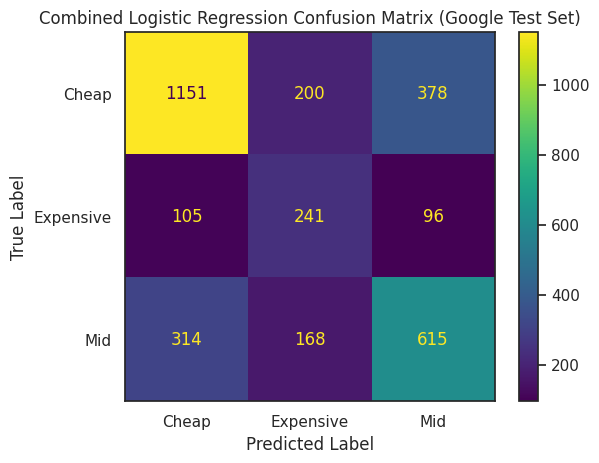

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_combined_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_combined_model.fit(X_train_combined, y_train)

y_pred_lr = lr_combined_model.predict(X_test_combined)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"--- Combined Logistic Regression (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_lr:.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=label_encoder.classes_))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')
plt.title("Combined Logistic Regression Confusion Matrix (Google Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from xgboost import XGBClassifier


xgb_combined_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_combined_model.fit(X_train_combined, y_train)


y_pred_xgb = xgb_combined_model.predict(X_test_combined)
macro_f1_xgb = f1_score(y_test, y_pred_xgb, average='macro')

print(f"--- Combined XGBoost (Google Test Set) ---")
print(f"Macro F1 Score: {macro_f1_xgb:.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=label_encoder.classes_))

--- Combined XGBoost (Google Test Set) ---
Macro F1 Score: 0.4187

              precision    recall  f1-score   support

       Cheap       0.58      0.97      0.72      1729
   Expensive       0.92      0.10      0.19       442
         Mid       0.77      0.22      0.35      1097

    accuracy                           0.60      3268
   macro avg       0.76      0.43      0.42      3268
weighted avg       0.69      0.60      0.52      3268



## Apple x Google

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report


apple_df = apple.copy()
google_df = google.copy()

text_col_apple = 'text_clean' if 'text_clean' in apple_df.columns else ('text' if 'text' in apple_df.columns else 'App_Name')
text_col_google = 'text_clean' if 'text_clean' in google_df.columns else ('text' if 'text' in google_df.columns else 'App Name')

apple_df['Rating'] = apple_df['Average_User_Rating']
apple_df['Rating_Count'] = apple_df['Reviews']
apple_df['Free'] = apple_df['Free'].astype(int)

google_df['Rating_Count'] = google_df['Rating Count'] if 'Rating Count' in google_df.columns else google_df['Rating_Count']
google_df['Free'] = google_df['Free'].astype(int)

num_cols = ['Rating', 'Rating_Count', 'Free']


common_price_classes = sorted(list(set(apple_df['Price_Class']).intersection(set(google_df['Price_Class']))))

apple_filtered = apple_df[apple_df['Price_Class'].isin(common_price_classes)].dropna(subset=[text_col_apple] + num_cols).copy()
google_filtered = google_df[google_df['Price_Class'].isin(common_price_classes)].dropna(subset=[text_col_google] + num_cols).copy()


label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(apple_filtered['Price_Class'])
y_test = label_encoder.transform(google_filtered['Price_Class'])

X_train_text = apple_filtered[text_col_apple].astype(str)
X_test_text = google_filtered[text_col_google].astype(str)

X_train_num = apple_filtered[num_cols].values
X_test_num = google_filtered[num_cols].values


scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)


X_train_combined = hstack([X_train_num_scaled, X_train_tfidf]).tocsr()
X_test_combined = hstack([X_test_num_scaled, X_test_tfidf]).tocsr()


max_len = 30
tokenizer = Tokenizer(char_level=True, lower=True, oov_token='<UNK>')
tokenizer.fit_on_texts(X_train_text)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_text), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test_text), maxlen=max_len, padding='post', truncating='post')

vocab_size = len(tokenizer.word_index) + 1
num_classes = len(common_price_classes)
num_features_len = len(num_cols)

--- Multimodal Logistic Regression (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4354

              precision    recall  f1-score   support

       Cheap       0.65      0.54      0.59      8646
   Expensive       0.23      0.51      0.32      2209
         Mid       0.45      0.35      0.40      5483

    accuracy                           0.47     16338
   macro avg       0.45      0.47      0.44     16338
weighted avg       0.53      0.47      0.49     16338



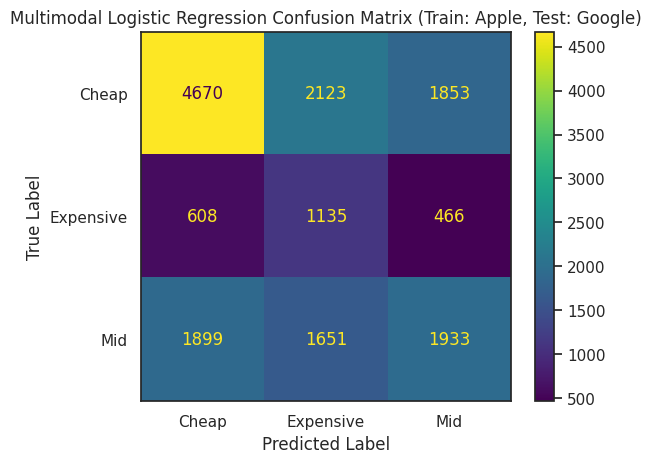

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model.fit(X_train_combined, y_train)

y_pred_lr = lr_model.predict(X_test_combined)
print(f"--- Multimodal Logistic Regression (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=common_price_classes
)

disp.plot(values_format='d')
plt.title("Multimodal Logistic Regression Confusion Matrix (Train: Apple, Test: Google)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_model.fit(X_train_combined, y_train)

y_pred_xgb = xgb_model.predict(X_test_combined)
print(f"--- Multimodal XGBoost (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_xgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=common_price_classes))

--- Multimodal XGBoost (Train: Apple, Test: Google) ---
Macro F1 Score: 0.2714

              precision    recall  f1-score   support

       Cheap       0.54      0.98      0.70      8646
   Expensive       0.26      0.01      0.03      2209
         Mid       0.62      0.05      0.09      5483

    accuracy                           0.54     16338
   macro avg       0.47      0.35      0.27     16338
weighted avg       0.53      0.54      0.40     16338



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_combined, y_train)

y_pred_rf = rf_model.predict(X_test_combined)
print(f"--- Multimodal Random Forest (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_rf, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=common_price_classes))

--- Multimodal Random Forest (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4230

              precision    recall  f1-score   support

       Cheap       0.59      0.81      0.68      8646
   Expensive       0.33      0.19      0.24      2209
         Mid       0.48      0.27      0.35      5483

    accuracy                           0.55     16338
   macro avg       0.47      0.42      0.42     16338
weighted avg       0.52      0.55      0.51     16338



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_combined, y_train)

y_pred_svm = svm_model.predict(X_test_combined)
print(f"--- Multimodal Linear SVM (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

--- Multimodal Linear SVM (Train: Apple, Test: Google) ---
Macro F1 Score: 0.4218

              precision    recall  f1-score   support

       Cheap       0.58      0.88      0.70      8646
   Expensive       0.43      0.18      0.26      2209
         Mid       0.51      0.22      0.31      5483

    accuracy                           0.56     16338
   macro avg       0.51      0.43      0.42     16338
weighted avg       0.54      0.56      0.51     16338



In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_model.fit(X_train_combined, y_train)

y_pred_mlp = mlp_model.predict(X_test_combined)
print(f"--- Multimodal Multi-Layer Perceptron (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mlp, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mlp, target_names=common_price_classes))

--- Multimodal Multi-Layer Perceptron (Train: Apple, Test: Google) ---
Macro F1 Score: 0.3944

              precision    recall  f1-score   support

       Cheap       0.57      0.90      0.70      8646
   Expensive       0.44      0.12      0.19      2209
         Mid       0.53      0.20      0.29      5483

    accuracy                           0.56     16338
   macro avg       0.51      0.41      0.39     16338
weighted avg       0.54      0.56      0.49     16338



In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, Dense, Dropout, concatenate
from tensorflow.keras.callbacks import EarlyStopping


text_input = Input(shape=(max_len,), name='text_input')
num_input = Input(shape=(num_features_len,), name='num_input')


x_text = Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len)(text_input)
x_text = Bidirectional(LSTM(units=64, dropout=0.2, recurrent_dropout=0.2))(x_text)


x_num = Dense(32, activation='relu')(num_input)


fused = concatenate([x_text, x_num])
x = Dense(64, activation='relu')(fused)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

bilstm_fusion_model = Model(inputs=[text_input, num_input], outputs=output)

bilstm_fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

bilstm_fusion_model.fit(
    [X_train_seq, X_train_num_scaled], y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_bilstm = np.argmax(bilstm_fusion_model.predict([X_test_seq, X_test_num_scaled]), axis=1)
print(f"--- BiLSTM Fusion (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_bilstm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_bilstm, target_names=common_price_classes))

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


759/759 ━━━━━━━━━━━━━━━━━━━━ 90s 107ms/step - accuracy: 0.5812 - loss: 0.9525 - val_accuracy: 0.6131 - val_loss: 0.9235
Epoch 2/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 79s 105ms/step - accuracy: 0.5848 - loss: 0.9388 - val_accuracy: 0.6146 - val_loss: 0.9062
Epoch 3/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 81s 107ms/step - accuracy: 0.5911 - loss: 0.9307 - val_accuracy: 0.6219 - val_loss: 0.8978
Epoch 4/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 80s 106ms/step - accuracy: 0.5964 - loss: 0.9241 - val_accuracy: 0.6269 - val_loss: 0.8897
Epoch 5/5
759/759 ━━━━━━━━━━━━━━━━━━━━ 81s 105ms/step - accuracy: 0.6015 - loss: 0.9158 - val_accuracy: 0.6281 - val_loss: 0.8866
511/511 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step
--- BiLSTM Fusion (Train: Apple, Test: Google) ---
Macro F1 Score: 0.2843

              precision    recall  f1-score   support

       Cheap       0.54      0.95      0.69      8646
   Expensive       0.18      0.04      0.06      2209
         Mid       0.47      0.06      0.10      5483

    accuracy             

In [ ]:
from tensorflow.keras.layers import LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D

text_input = Input(shape=(max_len,), name='text_input')
num_input = Input(shape=(num_features_len,), name='num_input')


embed = Embedding(input_dim=vocab_size, output_dim=64)(text_input)
attn_out = MultiHeadAttention(num_heads=4, key_dim=64)(embed, embed)
attn_out = Dropout(0.1)(attn_out)
x_text_trans = LayerNormalization(epsilon=1e-6)(embed + attn_out)

ffn = Dense(256, activation='relu')(x_text_trans)
ffn = Dense(64)(ffn)
ffn = Dropout(0.45)(ffn)
x_text_trans = LayerNormalization(epsilon=1e-6)(x_text_trans + ffn)
x_text_vec = GlobalAveragePooling1D()(x_text_trans)


x_num = Dense(32, activation='relu')(num_input)


fused = concatenate([x_text_vec, x_num])
x = Dense(64, activation='relu')(fused)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

transformer_fusion_model = Model(inputs=[text_input, num_input], outputs=output)

transformer_fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

transformer_fusion_model.fit(
    [X_train_seq, X_train_num_scaled], y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_transformer = np.argmax(transformer_fusion_model.predict([X_test_seq, X_test_num_scaled]), axis=1)
print(f"--- Transformer Fusion (Train: Apple, Test: Google) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_transformer, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_transformer, target_names=common_price_classes))

Epoch 1/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 127s 160ms/step - accuracy: 0.5806 - loss: 0.9576 - val_accuracy: 0.6146 - val_loss: 0.9053
Epoch 2/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 125s 137ms/step - accuracy: 0.5839 - loss: 0.9440 - val_accuracy: 0.6130 - val_loss: 0.9006
Epoch 3/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 140s 135ms/step - accuracy: 0.5860 - loss: 0.9394 - val_accuracy: 0.6157 - val_loss: 0.8995
Epoch 4/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 119s 157ms/step - accuracy: 0.5861 - loss: 0.9369 - val_accuracy: 0.6133 - val_loss: 0.8997
Epoch 5/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 103s 136ms/step - accuracy: 0.5888 - loss: 0.9349 - val_accuracy: 0.6165 - val_loss: 0.8994
Epoch 6/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 141s 135ms/step - accuracy: 0.5879 - loss: 0.9341 - val_accuracy: 0.6152 - val_loss: 0.9000
Epoch 7/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 108s 143ms/step - accuracy: 0.5887 - loss: 0.9314 - val_accuracy: 0.6171 - val_loss: 0.8973
Epoch 8/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 105s 139ms/step - accuracy: 0.5894 -

## Google x Apple

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import hstack
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import f1_score, classification_report


google_df = google.copy()
apple_df = apple.copy()

text_col_google = 'text_clean' if 'text_clean' in google_df.columns else ('text' if 'text' in google_df.columns else 'App Name')
text_col_apple = 'text_clean' if 'text_clean' in apple_df.columns else ('text' if 'text' in apple_df.columns else 'App_Name')

google_df['Rating_Count'] = google_df['Rating Count'] if 'Rating Count' in google_df.columns else google_df['Rating_Count']
google_df['Free'] = google_df['Free'].astype(int)

apple_df['Rating'] = apple_df['Average_User_Rating']
apple_df['Rating_Count'] = apple_df['Reviews']
apple_df['Free'] = apple_df['Free'].astype(int)

num_cols = ['Rating', 'Rating_Count', 'Free']


common_price_classes = sorted(list(set(google_df['Price_Class']).intersection(set(apple_df['Price_Class']))))

google_filtered = google_df[google_df['Price_Class'].isin(common_price_classes)].dropna(subset=[text_col_google] + num_cols).copy()
apple_filtered = apple_df[apple_df['Price_Class'].isin(common_price_classes)].dropna(subset=[text_col_apple] + num_cols).copy()

label_encoder = LabelEncoder()
label_encoder.fit(common_price_classes)

y_train = label_encoder.transform(google_filtered['Price_Class'])
y_test = label_encoder.transform(apple_filtered['Price_Class'])


X_train_text = google_filtered[text_col_google].astype(str)
X_test_text = apple_filtered[text_col_apple].astype(str)

X_train_num = google_filtered[num_cols].values
X_test_num = apple_filtered[num_cols].values


scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_tfidf, X_test_tfidf, tfidf_model = extract_tfidf_features(X_train_text, X_test_text)


X_train_combined = hstack([X_train_num_scaled, X_train_tfidf]).tocsr()
X_test_combined = hstack([X_test_num_scaled, X_test_tfidf]).tocsr()


max_len = 30
tokenizer = Tokenizer(char_level=True, lower=True, oov_token='<UNK>')
tokenizer.fit_on_texts(X_train_text)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_text), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test_text), maxlen=max_len, padding='post', truncating='post')

vocab_size = len(tokenizer.word_index) + 1
num_classes = len(common_price_classes)
num_features_len = len(num_cols)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    C= 3.5,
    random_state=42
)
lr_model.fit(X_train_combined, y_train)

y_pred_lr = lr_model.predict(X_test_combined)
print(f"--- Multimodal Logistic Regression (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_lr, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_lr, target_names=common_price_classes))

--- Multimodal Logistic Regression (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4030

              precision    recall  f1-score   support

       Cheap       0.63      0.81      0.71     33488
   Expensive       0.39      0.12      0.19      8352
         Mid       0.37      0.28      0.31     15242

    accuracy                           0.56     57082
   macro avg       0.46      0.40      0.40     57082
weighted avg       0.52      0.56      0.53     57082



In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_model.fit(X_train_combined, y_train)

y_pred_xgb = xgb_model.predict(X_test_combined)
print(f"--- Multimodal XGBoost (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_xgb, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_xgb, target_names=common_price_classes))

--- Multimodal XGBoost (Train: Google, Test: Apple) ---
Macro F1 Score: 0.2838

              precision    recall  f1-score   support

       Cheap       0.60      0.98      0.74     33488
   Expensive       0.40      0.01      0.02      8352
         Mid       0.41      0.05      0.10     15242

    accuracy                           0.59     57082
   macro avg       0.47      0.35      0.28     57082
weighted avg       0.52      0.59      0.46     57082



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    random_state=42
)
rf_model.fit(X_train_combined, y_train)

y_pred_rf = rf_model.predict(X_test_combined)
print(f"--- Multimodal Random Forest (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_rf, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=common_price_classes))

--- Multimodal Random Forest (Train: Google, Test: Apple) ---
Macro F1 Score: 0.3864

              precision    recall  f1-score   support

       Cheap       0.62      0.74      0.68     33488
   Expensive       0.26      0.13      0.17      8352
         Mid       0.34      0.29      0.31     15242

    accuracy                           0.53     57082
   macro avg       0.41      0.39      0.39     57082
weighted avg       0.49      0.53      0.50     57082



--- Multimodal Linear SVM (Train: Google, Test: Apple) ---
Macro F1 Score: 0.4048

              precision    recall  f1-score   support

       Cheap       0.63      0.80      0.70     33488
   Expensive       0.37      0.13      0.20      8352
         Mid       0.36      0.28      0.31     15242

    accuracy                           0.56     57082
   macro avg       0.45      0.40      0.40     57082
weighted avg       0.52      0.56      0.53     57082



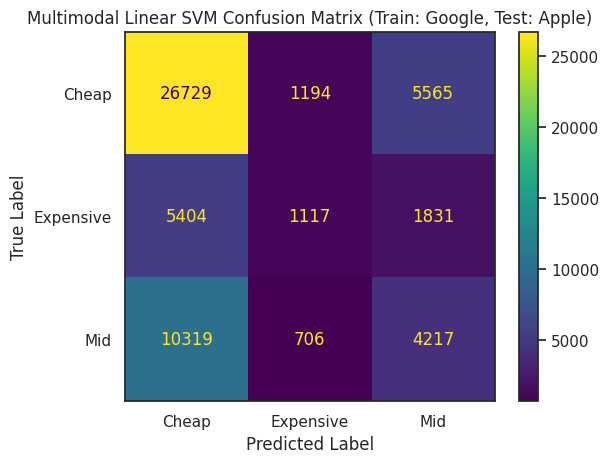

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


svm_model = LinearSVC(
    class_weight=None,
    max_iter=2000,
    random_state=42
)
svm_model.fit(X_train_combined, y_train)

y_pred_svm = svm_model.predict(X_test_combined)
print(f"--- Multimodal Linear SVM (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_svm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_svm, target_names=common_price_classes))

cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=common_price_classes
)

disp.plot(values_format='d')
plt.title("Multimodal Linear SVM Confusion Matrix (Train: Google, Test: Apple)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp_model.fit(X_train_combined, y_train)

y_pred_mlp = mlp_model.predict(X_test_combined)
print(f"--- Multimodal Multi-Layer Perceptron (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_mlp, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_mlp, target_names=common_price_classes))

--- Multimodal Multi-Layer Perceptron (Train: Google, Test: Apple) ---
Macro F1 Score: 0.3847

              precision    recall  f1-score   support

       Cheap       0.63      0.80      0.71     33488
   Expensive       0.40      0.07      0.12      8352
         Mid       0.36      0.30      0.33     15242

    accuracy                           0.56     57082
   macro avg       0.46      0.39      0.38     57082
weighted avg       0.52      0.56      0.52     57082



In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, Dense, Dropout, concatenate
from tensorflow.keras.callbacks import EarlyStopping


text_input = Input(shape=(max_len,), name='text_input')
num_input = Input(shape=(num_features_len,), name='num_input')


x_text = Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len)(text_input)
x_text = Bidirectional(LSTM(units=64, dropout=0.2, recurrent_dropout=0.2))(x_text)


x_num = Dense(32, activation='relu')(num_input)


fused = concatenate([x_text, x_num])
x = Dense(64, activation='relu')(fused)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

bilstm_fusion_model = Model(inputs=[text_input, num_input], outputs=output)

bilstm_fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

bilstm_fusion_model.fit(
    [X_train_seq, X_train_num_scaled], y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_bilstm = np.argmax(bilstm_fusion_model.predict([X_test_seq, X_test_num_scaled]), axis=1)
print(f"--- BiLSTM Fusion (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_bilstm, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_bilstm, target_names=common_price_classes))

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


434/434 ━━━━━━━━━━━━━━━━━━━━ 63s 123ms/step - accuracy: 0.5275 - loss: 0.9754 - val_accuracy: 0.5288 - val_loss: 0.9733
Epoch 2/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 69s 93ms/step - accuracy: 0.5364 - loss: 0.9620 - val_accuracy: 0.5369 - val_loss: 0.9668
Epoch 3/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 39s 89ms/step - accuracy: 0.5428 - loss: 0.9540 - val_accuracy: 0.5390 - val_loss: 0.9601
Epoch 4/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 44s 96ms/step - accuracy: 0.5527 - loss: 0.9453 - val_accuracy: 0.5422 - val_loss: 0.9566
Epoch 5/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 81s 94ms/step - accuracy: 0.5509 - loss: 0.9400 - val_accuracy: 0.5483 - val_loss: 0.9492
Epoch 6/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 39s 90ms/step - accuracy: 0.5555 - loss: 0.9351 - val_accuracy: 0.5463 - val_loss: 0.9474
Epoch 7/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 42s 97ms/step - accuracy: 0.5584 - loss: 0.9294 - val_accuracy: 0.5528 - val_loss: 0.9394
Epoch 8/25
434/434 ━━━━━━━━━━━━━━━━━━━━ 40s 93ms/step - accuracy: 0.5635 - loss: 0.9208 - val_accura

In [ ]:
from tensorflow.keras.layers import LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Dense, Dropout, concatenate
from tensorflow.keras.callbacks import EarlyStopping

text_input = Input(shape=(max_len,), name='text_input')
num_input = Input(shape=(num_features_len,), name='num_input')


embed = Embedding(input_dim=vocab_size, output_dim=64)(text_input)
attn_out = MultiHeadAttention(num_heads=4, key_dim=64)(embed, embed)
attn_out = Dropout(0.1)(attn_out)
x_text_trans = LayerNormalization(epsilon=1e-6)(embed + attn_out)

ffn = Dense(128, activation='relu')(x_text_trans)
ffn = Dense(64)(ffn)
ffn = Dropout(0.2)(ffn)
x_text_trans = LayerNormalization(epsilon=1e-6)(x_text_trans + ffn)
x_text_vec = GlobalAveragePooling1D()(x_text_trans)


x_num = Dense(32, activation='relu')(num_input)


fused = concatenate([x_text_vec, x_num])
x = Dense(64, activation='relu')(fused)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

transformer_fusion_model = Model(inputs=[text_input, num_input], outputs=output)

transformer_fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

transformer_fusion_model.fit(
    [X_train_seq, X_train_num_scaled], y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping]
)

y_pred_transformer = np.argmax(transformer_fusion_model.predict([X_test_seq, X_test_num_scaled]), axis=1)
print(f"--- Transformer Fusion (Train: Google, Test: Apple) ---")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_transformer, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred_transformer, target_names=common_price_classes))

Epoch 1/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 51s 211ms/step - accuracy: 0.5157 - loss: 0.9908 - val_accuracy: 0.5300 - val_loss: 0.9823
Epoch 2/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 28s 127ms/step - accuracy: 0.5306 - loss: 0.9745 - val_accuracy: 0.5292 - val_loss: 0.9760
Epoch 3/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 27s 125ms/step - accuracy: 0.5316 - loss: 0.9704 - val_accuracy: 0.5296 - val_loss: 0.9760
Epoch 4/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 34s 156ms/step - accuracy: 0.5298 - loss: 0.9694 - val_accuracy: 0.5288 - val_loss: 0.9747
Epoch 5/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - accuracy: 0.5316 - loss: 0.9668 - val_accuracy: 0.5296 - val_loss: 0.9723
Epoch 6/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 49s 152ms/step - accuracy: 0.5342 - loss: 0.9643 - val_accuracy: 0.5267 - val_loss: 0.9734
Epoch 7/10
217/217 ━━━━━━━━━━━━━━━━━━━━ 32s 146ms/step - accuracy: 0.5371 - loss: 0.9617 - val_accuracy: 0.5247 - val_loss: 0.9742
1784/1784 ━━━━━━━━━━━━━━━━━━━━ 57s 32ms/step
--- Transformer Fusion (Train: Google,

# **MODEL EVALUATION**

,Model,Accuracy,Precision,Recall,Macro F1
0,Textual - Google x Google (Logistic Regression),0.6100,0.5600,0.5800,0.5700
1,Multimodal - Google x Google (Logistic Regression),0.6100,0.5600,0.5900,0.5700
2,Textual - Apple x Apple (Linear SVM),0.6300,0.5400,0.5200,0.5300
3,Multimodal - Apple x Apple (Logistic Regression),0.6700,0.6500,0.5000,0.5200
4,Multimodal Cross - Apple to Google (Logistic Regression),0.4700,0.4500,0.4700,0.4400
5,Textual Cross - Apple to Google (Complement Naive Bayes),0.5000,0.4400,0.4400,0.4300
6,Textual Cross - Google to Apple (Logistic Regression),0.5100,0.4200,0.4200,0.4100
7,Multimodal Cross - Google to Apple (Linear SVM),0.5600,0.4500,0.4000,0.4000
8,Numerical - Apple x Apple (Logistic Regression),0.5300,0.4000,0.3900,0.3700
9,Numerical - Google x Google (Random Forest),0.4100,0.3800,0.3900,0.3700


/tmp/ipykernel_437/2052565327.py:113: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


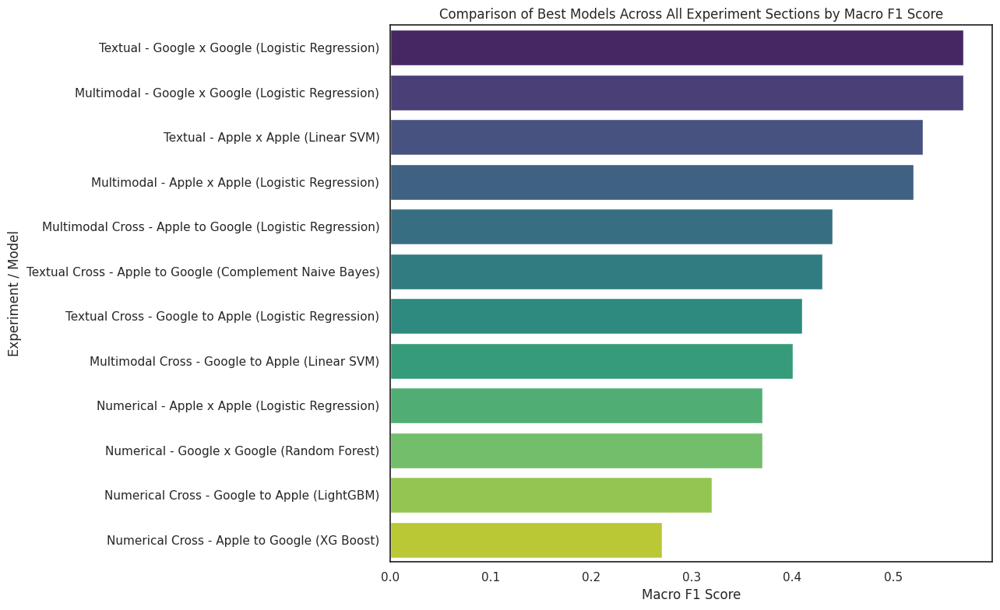

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


model_results = [
    {
        "Model": "Numerical - Apple x Apple (Logistic Regression)",
        "Accuracy": 0.53,
        "Precision": 0.40,
        "Recall": 0.39,
        "Macro F1": 0.37
    },
    {
        "Model": "Numerical - Google x Google (Random Forest)",
        "Accuracy": 0.41,
        "Precision": 0.38,
        "Recall": 0.39,
        "Macro F1": 0.37
    },
    {
        "Model": "Textual - Apple x Apple (Linear SVM)",
        "Accuracy": 0.63,
        "Precision": 0.54,
        "Recall": 0.52,
        "Macro F1": 0.53
    },
    {
        "Model": "Textual - Google x Google (Logistic Regression)",
        "Accuracy": 0.61,
        "Precision": 0.56,
        "Recall": 0.58,
        "Macro F1": 0.57
    },
    {
        "Model": "Numerical Cross - Apple to Google (XG Boost)",
        "Accuracy": 0.53,
        "Precision": 0.33,
        "Recall": 0.34,
        "Macro F1": 0.27
    },
    {
        "Model": "Numerical Cross - Google to Apple (LightGBM)",
        "Accuracy": 0.50,
        "Precision": 0.34,
        "Recall": 0.34,
        "Macro F1": 0.32
    },
    {
        "Model": "Textual Cross - Apple to Google (Complement Naive Bayes)",
        "Accuracy": 0.50,
        "Precision": 0.44,
        "Recall": 0.44,
        "Macro F1": 0.43
    },
    {
        "Model": "Textual Cross - Google to Apple (Logistic Regression)",
        "Accuracy": 0.51,
        "Precision": 0.42,
        "Recall": 0.42,
        "Macro F1": 0.41
    },
    {
        "Model": "Multimodal - Apple x Apple (Logistic Regression)",
        "Accuracy": 0.67,
        "Precision": 0.65,
        "Recall": 0.50,
        "Macro F1": 0.52
    },
    {
        "Model": "Multimodal - Google x Google (Logistic Regression)",
        "Accuracy": 0.61,
        "Precision": 0.56,
        "Recall": 0.59,
        "Macro F1": 0.57
    },
    {
        "Model": "Multimodal Cross - Apple to Google (Logistic Regression)",
        "Accuracy": 0.47,
        "Precision": 0.45,
        "Recall": 0.47,
        "Macro F1": 0.44
    },
    {
        "Model": "Multimodal Cross - Google to Apple (Linear SVM)",
        "Accuracy": 0.56,
        "Precision": 0.45,
        "Recall": 0.40,
        "Macro F1": 0.40
    }
]


comparison_df = pd.DataFrame(model_results)


comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=comparison_df,
    x="Macro F1",
    y="Model",
    palette="viridis"
)

plt.title("Comparison of Best Models Across All Experiment Sections by Macro F1 Score")
plt.xlabel("Macro F1 Score")
plt.ylabel("Experiment / Model")
plt.tight_layout()
plt.show()